<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
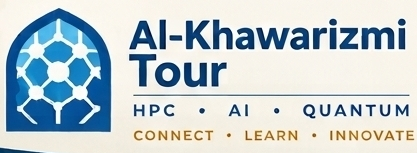
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 1 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Data Quality &amp; Preprocessing — Beijing Air Quality · Hands-on &amp; Week-1 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos used during the lecture (slide references in each heading) · Part B: the week-long <b>Air-Quality Data Challenge</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A11) | during the 2-hour lecture | each demo matches a slide of the deck / a card of the speaker script |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells, write your report, prepare your pitch |

**Dataset:** *Beijing Multi-Site Air Quality* — UCI Machine Learning Repository, dataset 501. Hourly PM2.5, PM10, SO2, NO2, CO, O3 (µg/m³) and TEMP, PRES, DEWP, RAIN, wind direction `wd`, wind speed `WSPM` at **12 stations**, **1 Mar 2013 – 28 Feb 2017**, **420,768 rows**, with real missing values (NA).
Reference: Zhang, S. et al. (2017) *Cautionary tales on air-quality improvement in Beijing*, Proc. R. Soc. A.

**Data access:** the notebook downloads the archive from UCI (≈ 8 MB) and caches it. If you already have the `PRSA_Data_*.csv` files, put them next to the notebook. Offline, a synthetic stand-in with the same columns is generated so the code still runs.

**Requirements:** Python ≥ 3.9, `numpy`, `pandas`, `matplotlib`, `scikit-learn ≥ 1.2`. Works in Jupyter, VS Code or Google Colab. Tip: on a laptop, run Part A first on `SAMPLE_STATIONS` (4 stations) and switch to all 12 for the challenge.

## 0 · Setup — set your team number first

In [61]:
TEAM_ID = 1013           # <-- your team number: it seeds YOUR version of the merged dataset
SEED = 1000 + TEAM_ID

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)
import sklearn; print("scikit-learn", sklearn.__version__, "| team", TEAM_ID)

scikit-learn 1.9.1 | team 1013


---
# Part A · Guided demos
## A1 · Load the 12 station files  *(slides 2 & 13)*

In [62]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw.head()

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## A2 · The scenario: a careless merge + an untouched final year  *(slides 27 & 32)*
* **Test year** = 1 Mar 2016 – 28 Feb 2017 (the real data, untouched) — used **only in Task 6**.
* **Training years** = 1 Mar 2013 – 29 Feb 2016 → turned into your team's *merged export* with realistic merge errors.

In [63]:
SPLIT = pd.Timestamp("2016-03-01")
train_raw = raw[raw["datetime"] < SPLIT].reset_index(drop=True)
test_year = raw[raw["datetime"] >= SPLIT].reset_index(drop=True)
print(f"training years: {len(train_raw):,} rows | test year: {len(test_year):,} rows")

training years: 315,648 rows | test year: 105,120 rows


## A3 · Generate your team's merged export
The function reproduces problems of a careless multi-station merge. **Treat it as a black box during the challenge** — your job is to *discover* the problems from the data.

In [64]:
def make_dirty(df, seed):
    r = np.random.default_rng(seed)
    d = df.drop(columns=["datetime"]).copy()
    n = len(d)
    st_unit, st_tz, st_stuck = r.choice(STATIONS, 3, replace=False)
    # 1) consistency: station-name variants and lower-case wind directions
    v = r.random(n)
    d.loc[v < .05, "station"] = d.loc[v < .05, "station"].str.upper()
    d.loc[(v >= .05) & (v < .10), "station"] = d.loc[(v >= .05) & (v < .10), "station"].str.lower() + " "
    w = r.random(n) < .02
    d.loc[w, "wd"] = d.loc[w, "wd"].str.lower()
    stn = d["station"].str.strip().str.title()
    # 2) accuracy: one station exported CO in mg/m3 during 2014
    m = (stn == st_unit) & (d["year"] == 2014)
    d.loc[m, "CO"] = d.loc[m, "CO"] / 1000
    # 3) timeliness: one station exported in UTC during 2015 (8 h behind Beijing time)
    m = (stn == st_tz) & (d["year"] == 2015)
    dt = pd.to_datetime(d.loc[m, ["year", "month", "day", "hour"]]) - pd.Timedelta(hours=8)
    d.loc[m, "year"], d.loc[m, "month"], d.loc[m, "day"], d.loc[m, "hour"] = dt.dt.year, dt.dt.month, dt.dt.day, dt.dt.hour
    # 4) validity: stuck PM2.5 sensor (flat lines), sentinel codes, PM2.5/PM10 column swap
    idx = np.flatnonzero((stn == st_stuck).values)
    for s0 in r.choice(idx[:-80], 8, replace=False):
        L = int(r.integers(24, 73)); rows = d.index[s0:s0 + L]
        d.loc[rows, "PM2.5"] = d.loc[rows[0], "PM2.5"]
    for c in ["TEMP", "PRES"]:
        d.loc[r.random(n) < .002, c] = -999
    sw = r.random(n) < .003
    d.loc[sw, ["PM2.5", "PM10"]] = d.loc[sw, ["PM10", "PM2.5"]].values
    # 5) completeness: extra random logger drop-outs in NO2
    d.loc[r.random(n) < .03, "NO2"] = np.nan
    # 6) uniqueness: one station-month re-uploaded (slightly different O3) + scattered exact duplicates
    s_dup = r.choice(STATIONS); y_dup, m_dup = 2014, int(r.integers(1, 13))
    re = d[(stn == s_dup) & (d["year"] == y_dup) & (d["month"] == m_dup)].copy()
    re["O3"] = re["O3"] + 1
    d = pd.concat([d, re, d.sample(frac=.005, random_state=seed)], ignore_index=True)
    return d.sample(frac=1, random_state=seed).reset_index(drop=True)

dirty = make_dirty(train_raw, SEED)
dirty.to_csv(f"beijing_merged_team{TEAM_ID}.csv.gz", index=False)
print(f"merged export: {dirty.shape[0]:,} rows -> beijing_merged_team{TEAM_ID}.csv.gz")
dirty.head()

merged export: 317,946 rows -> beijing_merged_team1013.csv.gz


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,9079,2014,3,14,6,7.0,22.0,2.0000,14.0000,200.0,75.0,3.7,1018.2,-12.7,0.0,NE,0.7,Shunyi
1,13489,2014,9,14,0,77.0,103.0,10.0000,38.0000,700.0,105.0,22.0,1009.6,14.9,0.0,WSW,1.4,Tiantan
2,21688,2015,8,21,15,13.0,27.0,2.0000,12.0000,400.0,172.0,33.6,995.8,14.1,0.0,WSW,1.5,Gucheng
3,3354,2013,7,18,17,175.0,144.0,13.1376,36.1328,NaN,114.0,27.6,999.6,23.0,0.0,S,2.2,Dongsi
4,15477,2014,12,5,20,47.0,47.0,20.0000,33.0000,1200.0,24.0,-2.2,1022.0,-20.1,0.0,N,1.3,Dingling


## A4 · First look  *(slides 11, 13 & 14)*

In [65]:
df = dirty.copy()
print("shape:", df.shape, "\n")
print(df.dtypes, "\n")
print("fraction missing:\n", df.isna().mean().round(4).sort_values(ascending=False), "\n")
print("duplicate station-hours:", df.duplicated(subset=KEY).sum())
print("station labels:", df["station"].nunique(), "distinct (expected 12)")

shape: (317946, 18) 

No           int64
year         int64
month        int64
day          int64
hour         int64
PM2.5      float64
PM10       float64
SO2        float64
NO2        float64
CO         float64
O3         float64
TEMP       float64
PRES       float64
DEWP       float64
RAIN       float64
wd             str
WSPM       float64
station        str
dtype: object 

fraction missing:
 NO2        0.0596
CO         0.0572
O3         0.0322
SO2        0.0221
PM2.5      0.0202
PM10       0.0146
wd         0.0021
RAIN       0.0006
DEWP       0.0006
PRES       0.0006
WSPM       0.0006
TEMP       0.0006
year       0.0000
No         0.0000
day        0.0000
month      0.0000
hour       0.0000
station    0.0000
dtype: float64 

duplicate station-hours: 2306
station labels: 36 distinct (expected 12)


In [66]:
# mean vs median per station -> skew; min / max -> impossible values
df.groupby(df["station"].str.strip().str.title())[["PM2.5", "CO", "TEMP", "PRES"]].agg(["mean", "median", "min", "max"]).round(1)

PM2.5                         CO                          TEMP  \
               mean median  min    max    mean  median    min      max  mean   
station                                                                        
Aotizhongxin   83.7   60.0  3.0  898.0  1272.4   900.0  100.0  10000.0  11.2   
Changping      72.4   47.0  2.0  882.0  1146.0   800.0  100.0  10000.0  11.7   
Dingling       66.9   41.0  3.0  881.0   908.0   600.0  100.0   9400.0  11.7   
Dongsi         85.7   61.0  3.0  737.0  1339.6  1000.0  100.0  10000.0  10.9   
Guanyuan       82.4   59.0  3.0  680.0  1289.9   900.0  100.0  10000.0  11.4   
Gucheng        83.9   61.0  2.0  770.0  1354.3  1000.0  100.0   9900.0  12.1   
Huairou        71.2   48.0  2.0  762.0  1035.3   800.0  100.0  10000.0  10.9   
Nongzhanguan   85.4   60.0  3.0  844.0   862.2   500.0    0.1  10000.0  11.6   
Shunyi         80.2   56.0  3.0  941.0  1188.2   900.0  100.0  10000.0  11.1   
Tiantan        82.8   60.0  3.0  821.0  1307.5  1000.0  100.0  10000.0  11.2   
Wanliu         85.3   61.0  3.0  957.0  1335.0   900.0  100.0  10000.0  11.1   
Wanshouxigong  84.8   61.0  3.0  999.0  1395.9  1000.0  100.0   9800.0  11.1   

                                     PRES                         
              median    min   max    mean  median    min     max  
station                                                           
Aotizhongxin    14.3 -999.0  40.5  1007.5  1011.2 -999.0  1041.8  
Changping       14.6 -999.0  41.4  1003.7  1007.5 -999.0  1036.5  
Dingling        14.6 -999.0  41.4  1004.2  1007.5 -999.0  1036.5  
Dongsi          14.5 -999.0  41.1  1007.4  1012.2 -999.0  1042.0  
Guanyuan        14.3 -999.0  40.5  1007.2  1011.2 -999.0  1042.0  
Gucheng         14.8 -999.0  41.6  1004.3  1008.6 -999.0  1038.1  
Huairou         13.4 -999.0  40.3  1004.4  1007.3 -999.0  1036.5  
Nongzhanguan    14.6 -999.0  41.1  1007.8  1012.2 -999.0  1042.0  
Shunyi          14.3 -999.0  40.6  1008.8  1012.7 -999.0  1042.8  
Tiantan         14.4 -999.0  41.1  1009.1  1012.3 -999.0  1042.0  
Wanliu          14.2 -999.0  40.5  1007.6  1010.8 -999.0  1040.3  
Wanshouxigong   14.6 -999.0  40.6  1006.4  1010.6 -999.0  1042.0

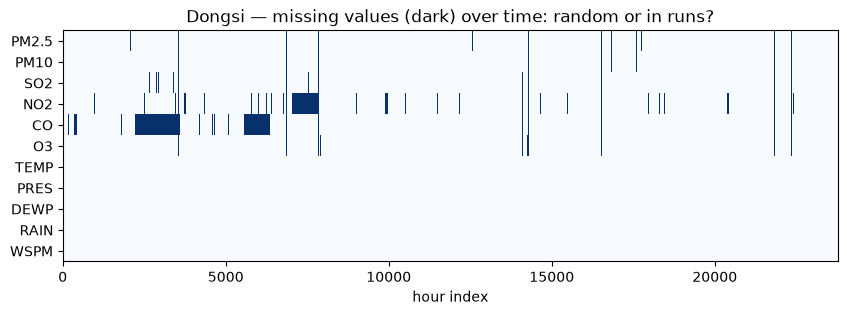

In [67]:
# missing-value matrix for one station (rows = hours in time order)
one = df[df["station"] == "Dongsi"].sort_values(["year", "month", "day", "hour"])
plt.figure(figsize=(10, 3))
plt.imshow(one[POLLUTANTS + WEATHER].isna().values.T, aspect="auto", interpolation="nearest", cmap="Blues")
plt.yticks(range(len(POLLUTANTS + WEATHER)), POLLUTANTS + WEATHER); plt.xlabel("hour index"); plt.grid(False)
plt.title("Dongsi — missing values (dark) over time: random or in runs?"); plt.show()

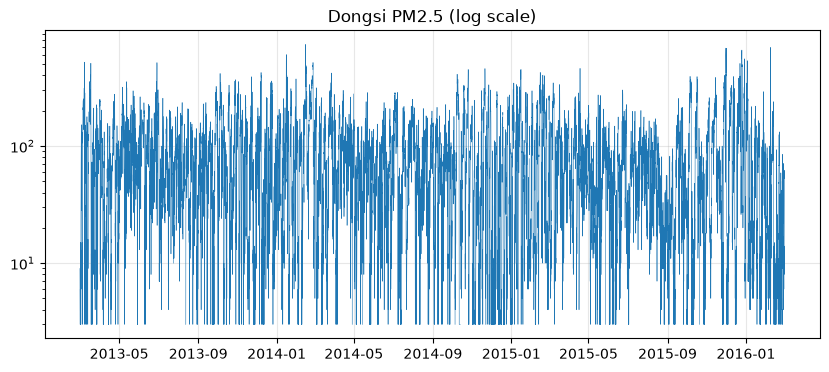

In [68]:
# the single most useful plot: a time series per station
one_dt = pd.to_datetime(one[["year", "month", "day", "hour"]])
plt.plot(one_dt, one["PM2.5"], lw=.4); plt.yscale("log"); plt.title("Dongsi PM2.5 (log scale)"); plt.show()

## A5 · Consistency: canonical labels  *(slide 21)*

In [69]:
print(df["station"].value_counts().head(15))
canon = df["station"].str.strip().str.title()
print("\nafter strip + title:", canon.nunique(), "stations")
print("wind directions:", sorted(df["wd"].dropna().unique()))

station
Nongzhanguan      24430
Tiantan           23833
Wanliu            23813
Changping         23804
Aotizhongxin      23793
Shunyi            23785
Gucheng           23782
Huairou           23779
Dongsi            23772
Dingling          23760
Guanyuan          23748
Wanshouxigong     23698
wanshouxigong      1432
NONGZHANGUAN       1407
DINGLING           1375
Name: count, dtype: int64

after strip + title: 12 stations
wind directions: ['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE', 'SSW', 'SW', 'W', 'WNW', 'WSW', 'e', 'ene', 'ese', 'n', 'ne', 'nne', 'nnw', 'nw', 's', 'se', 'sse', 'ssw', 'sw', 'w', 'wnw', 'wsw']


## A6 · Outliers, stuck sensors and physics checks  *(slides 19 & 20)*

In [70]:
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

PM2.5 > PM10 (impossible)    21914
negative concentrations          0
sentinel -999 codes           1292
PRES outside 950-1060 hPa      649
Name: rows, dtype: int64

In [71]:
def hampel_flags(s, window=25, k=3.0):
    med = s.rolling(window, center=True, min_periods=5).median()
    mad = (s - med).abs().rolling(window, center=True, min_periods=5).median()
    return (s - med).abs() > k * 1.4826 * mad

def stuck_flags(s, hours=12):
    return s.rolling(hours).std() == 0

res = {}
for st, g in df.assign(station=canon).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()), "stuck >= 12 h": int(stuck_flags(g["PM2.5"]).sum())}
pd.DataFrame(res).T.sort_values("stuck >= 12 h", ascending=False)

,Hampel spikes,stuck >= 12 h
Guanyuan,1140,171
Dongsi,1242,36
Wanshouxigong,1112,24
Huairou,1340,17
Nongzhanguan,1262,4
Dingling,1545,0
Aotizhongxin,1203,0
Changping,1195,0
Gucheng,1250,0
Shunyi,1161,0


## A7 · Imputation study — single hours vs 24-hour gaps  *(slide 18)*
We hide values we **know** (clean reference = the original training years, demo only) and measure the RMSE of each imputer.

In [72]:
from sklearn.impute import KNNImputer
piv = train_raw.pivot_table(index="datetime", columns="station", values="NO2")   # hours x stations
target_st = "Dongsi"
truth = piv[target_st]
known = np.flatnonzero(truth.notna().values)

def make_mask(kind):
    m = np.zeros(len(truth), bool)
    if kind == "single hours":
        m[rng.choice(known, len(known) // 10, replace=False)] = True
    else:                                                    # 24-h blocks
        for s0 in rng.choice(known[:-30], 150, replace=False):
            m[s0:s0 + 24] = True
        m &= truth.notna().values
    return m

def evaluate(mask):
    s = truth.mask(mask)
    others = piv.drop(columns=target_st)
    nb = others.mean(axis=1)
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.Series(KNNImputer(n_neighbors=5).fit_transform(piv.assign(**{target_st: s}))[:, list(piv.columns).index(target_st)], index=s.index),
    }
    return {k: np.sqrt(np.mean((v.fillna(s.mean()).values[mask] - truth.values[mask]) ** 2)) for k, v in cand.items()}

t0 = time.perf_counter()
study = pd.DataFrame({kind: evaluate(make_mask(kind)) for kind in ["single hours", "24-h blocks"]}).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE of NO2 in µg/m³ — lower is better")
study

(26.5 s)  RMSE of NO2 in µg/m³ — lower is better


,single hours,24-h blocks
mean,32.39,32.77
median,33.08,33.21
time interpolation,7.26,28.21
neighbour stations,13.56,13.26
KNN across stations,9.58,9.79


## A8 · Skewness and transformations  *(slides 12 & 25)*

skewness raw:
 PM2.5    1.93
SO2      2.74
CO       2.45
NO2      1.03
O3       1.75
WSPM     1.67
dtype: float64

skewness after log1p:
 PM2.5   -0.33
SO2      0.42
CO      -0.00
NO2     -0.72
O3      -0.59
WSPM     0.29
dtype: float64


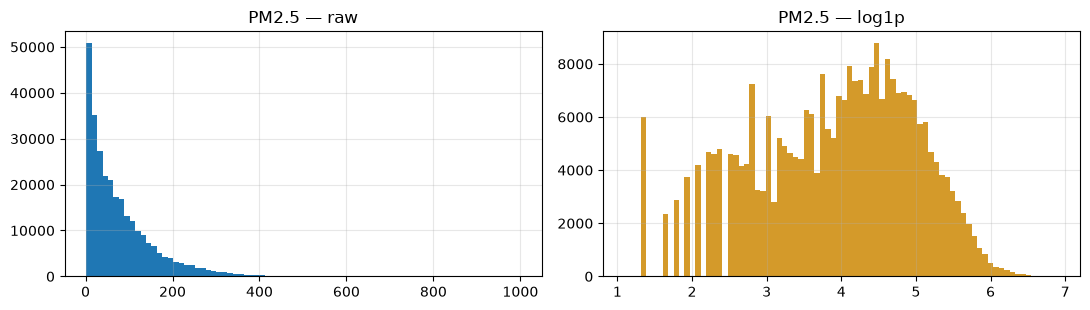

In [73]:
from sklearn.preprocessing import PowerTransformer
vals = train_raw[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
print("skewness raw:\n", vals.skew().round(2))
print("\nskewness after log1p:\n", np.log1p(vals).skew().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals["PM2.5"], bins=80); ax[0].set_title("PM2.5 — raw")
ax[1].hist(np.log1p(vals["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 — log1p")
plt.tight_layout(); plt.show()

## A9 · Multicollinearity — VIF  *(slide 22)*

In [74]:
def vif(frame):
    X = (frame - frame.mean()) / frame.std()
    out = {}
    for c in X.columns:
        Aa = np.column_stack([np.ones(len(X)), X.drop(columns=c).values])
        coef, *_ = np.linalg.lstsq(Aa, X[c].values, rcond=None)
        resid = X[c].values - Aa @ coef
        out[c] = 1 / max(1 - (1 - (resid ** 2).sum() / ((X[c] - X[c].mean()) ** 2).sum()), 1e-12)
    return pd.Series(out, name="VIF").sort_values(ascending=False).round(2)

vif(train_raw[["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "WSPM"]].dropna().sample(50_000, random_state=0))

TEMP    7.83
DEWP    5.75
PRES    3.14
NO2     2.62
CO      2.52
O3      2.23
SO2     1.83
WSPM    1.60
Name: VIF, dtype: float64

## A10 · Leakage demo — random split vs time split  *(slides 27 & 28)*
Same model, same data, two ways of splitting. The random split lets near-identical neighbouring hours sit on both sides.

In [75]:
def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

def make_pipeline(model):
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    return Pipeline([("prep", prep), ("model", model)])

ref = add_features(train_raw.drop(columns=["datetime"])).dropna(subset=[TARGET]).sort_values("datetime")
ref = ref.iloc[::3]                                   # every 3rd hour keeps the demo fast
X_ref, y_ref = ref[NUM_FEATS + CAT_FEATS], ref[TARGET]
hgb = make_pipeline(HistGradientBoostingRegressor(max_iter=200, random_state=0))
for name, cv in [("random KFold", KFold(5, shuffle=True, random_state=0)), ("TimeSeriesSplit", TimeSeriesSplit(5))]:
    s = cross_val_score(hgb, X_ref, y_ref, cv=cv, scoring="neg_root_mean_squared_error")
    print(f"{name:16s} CV RMSE = {-s.mean():6.2f} ± {s.std():.2f} µg/m³")

random KFold     CV RMSE =  29.71 ± 0.19 µg/m³
TimeSeriesSplit  CV RMSE =  42.32 ± 10.22 µg/m³


## A11 · Template: a leak-free, time-aware pipeline  *(slide 29)*
`make_pipeline` above is the template you adapt in Task 5. Everything that *learns* (imputers, scalers, encoders) lives **inside** it, so it is re-fitted in every fold.

---
# Part B · Week-1 Team Challenge — *The Air-Quality Data Challenge*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The city’s environmental agency merged the exports of its <b>12 monitoring stations</b> (1 Mar 2013 – 29 Feb 2016) for an AI project. On top of the real gaps, the merge introduced errors. Your file <code>beijing_merged_team&lt;N&gt;.csv.gz</code> (created in A3) is your team’s version. <br><b>Goal:</b> deliver a documented, leak-free pipeline for a <b>virtual PM2.5 sensor</b> — estimate PM2.5 from gases, weather, time and station, <b>without PM10</b> (same instrument, down at the same time) — and <b>prove with numbers</b> how much your data work improves it on the untouched test year.</div>

| # | Task | Points |
|---|---|---|
| 1 | Data-quality audit (six dimensions, gap lengths, missingness by station) | 15 |
| 2 | Consistency, validity & timeliness fixes | 15 |
| 3 | Imputation study (≥ 3 imputers incl. one time-aware) | 15 |
| 4 | Outliers: stuck sensors & spikes vs real episodes; transformations | 10 |
| 5 | Leak-free pipeline + `TimeSeriesSplit` CV | 15 |
| 6 | Impact study on the test year | 20 |
| ★ | HPC bonus: parallel per-station cleaning | +10 |
|   | 1-page report + 5-min pitch | 10 |

**Rules:** `test_year` only in Task 6 · justify every decision in one line · keep `SEED` fixed · start from `beijing_merged_team<N>.csv.gz`, not from `train_raw`.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–5 · Day 5 Task 6 (+ bonus) · Days 6–7 report & pitch.

**Hint — what kinds of problems to look for:** label variants, a unit mix-up, a time-zone shift, re-uploaded data, stuck sensors, sentinel codes, physically impossible values, extra drop-outs. *Which station, which column, which period? That is for you to find.*

## Task 1 · Data-quality audit (15 pts)

In [76]:
df = pd.read_csv(f"beijing_merged_team{TEAM_ID}.csv.gz")

# TODO 1a completeness: % missing per column AND per station; gap-length distribution (see slide 17 code)
missing_per_column = (
    df.isna()
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
      .rename("Missing (%)")
      .to_frame()
)

missing_per_column

,Missing (%)
NO2,5.96
CO,5.72
O3,3.22
SO2,2.21
PM2.5,2.02
PM10,1.46
wd,0.21
RAIN,0.06
DEWP,0.06
PRES,0.06


In [77]:
missing_per_station = (
    df.drop(columns=["station","No"])
      .isna()
      .groupby(df["station"])
      .mean()
      .mul(100)
      .round(2)
)
print("Missing values (%)")
missing_per_station

Missing values (%)


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM
station,,,,,,,,,,,,,,,,
AOTIZHONGXIN,0.0,0.0,0.0,0.0,2.78,2.32,2.47,6.41,6.56,5.48,0.08,0.08,0.08,0.08,0.08,0.08
Aotizhongxin,0.0,0.0,0.0,0.0,2.86,2.31,3.04,6.09,6.17,5.56,0.00,0.00,0.00,0.00,0.04,0.00
CHANGPING,0.0,0.0,0.0,0.0,2.94,2.18,1.96,5.50,5.20,2.18,0.00,0.00,0.00,0.00,0.08,0.00
Changping,0.0,0.0,0.0,0.0,2.49,1.84,1.88,4.86,5.24,1.89,0.13,0.13,0.13,0.14,0.28,0.13
DINGLING,0.0,0.0,0.0,0.0,2.25,1.96,2.55,7.49,7.35,2.98,0.00,0.00,0.00,0.00,0.22,0.00
DONGSI,0.0,0.0,0.0,0.0,1.31,0.95,1.17,7.37,10.72,1.24,0.00,0.00,0.00,0.00,0.00,0.00
Dingling,0.0,0.0,0.0,0.0,1.86,1.86,1.98,6.77,6.66,2.87,0.14,0.13,0.14,0.14,0.29,0.13
Dongsi,0.0,0.0,0.0,0.0,1.41,0.91,1.30,7.53,10.84,1.22,0.01,0.01,0.01,0.01,0.03,0.01
GUANYUAN,0.0,0.0,0.0,0.0,1.58,1.13,1.58,5.65,6.63,4.29,0.00,0.00,0.00,0.00,0.08,0.00


In [78]:
summary = []

for station in STATIONS:
    one = df[df["station"] == station].sort_values(["year", "month", "day", "hour"])
    for el in WEATHER + POLLUTANTS:
        missings = one[el].isna()
        groups = missings.ne(missings.shift()).cumsum()
        gap_len = missings[missings].groupby(groups[missings]).size()

        summary.append({
            "station": station,
            "variable": el,
            "num_of_gaps": len(gap_len),
            "longest_gap": gap_len.max(),
            "mean_gap": gap_len.mean(),
            "median_gap": gap_len.median()
        })

gap_len_fr = pd.DataFrame(summary)
gap_len_fr = gap_len_fr.set_index(["station", "variable"]).sort_index()

gap_len_fr

num_of_gaps  longest_gap  mean_gap  median_gap
station       variable                                                
Aotizhongxin  CO                281          315  5.224199         1.0
              DEWP                1            1  1.000000         1.0
              NO2               843          315  1.717675         1.0
              O3                408          315  3.240196         1.0
              PM10              102          315  5.382353         1.0
...                             ...          ...       ...         ...
Wanshouxigong PRES                1            1  1.000000         1.0
              RAIN                1            1  1.000000         1.0
              SO2                95           88  4.715789         1.0
              TEMP                1            1  1.000000         1.0
              WSPM                1            1  1.000000         1.0

[132 rows x 4 columns]

In [79]:
# TODO 1b uniqueness: duplicate station-hours (KEY); are duplicates identical or slightly different?
dup_mask = df.duplicated(subset=KEY, keep=False)
print(f"duplicate station-hours rows involving: {dup_mask.sum()}")

duplicated = df[dup_mask].sort_values(KEY)
duplicated

duplicate station-hours rows involving: 4609


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
3030,2822,2013,6,26,13,207.0,202.0,6.5688,69.5967,NaN,185.283,30.5,990.4,22.1,0.0,SW,2.6,AOTIZHONGXIN
45171,2822,2013,6,26,13,207.0,202.0,6.5688,69.5967,NaN,185.283,30.5,990.4,22.1,0.0,SW,2.6,AOTIZHONGXIN
4459,9483,2014,3,31,2,129.0,279.0,24.0000,82.0000,1100.0,39.000,13.9,1009.4,6.0,0.0,ESE,0.1,AOTIZHONGXIN
96658,9483,2014,3,31,2,129.0,279.0,24.0000,82.0000,1100.0,39.000,13.9,1009.4,6.0,0.0,ESE,0.1,AOTIZHONGXIN
13514,13552,2014,9,16,15,40.0,92.0,7.0000,94.0000,600.0,15.000,20.1,1012.0,11.3,0.0,ENE,0.8,AOTIZHONGXIN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148403,18876,2015,4,26,11,156.0,253.0,30.0000,90.0000,1400.0,119.000,27.0,1007.1,12.2,0.0,SSW,1.9,wanshouxigong
45584,22377,2015,9,19,8,12.0,12.0,2.0000,49.0000,500.0,17.000,20.0,1015.1,9.0,0.0,NNE,2.2,wanshouxigong
137348,22377,2015,9,19,8,12.0,12.0,2.0000,49.0000,500.0,17.000,20.0,1015.1,9.0,0.0,NNE,2.2,wanshouxigong
287367,24458,2015,12,15,1,10.0,10.0,4.0000,15.0000,500.0,56.000,3.2,1019.6,-11.6,0.0,WNW,5.8,wanshouxigong


`keep=False` also counts the first occurrence of each duplicate, and it helps us compairing the duplicated rows and ckeck wether they are **Identical** or **Slightly different**

In [80]:
dup_groups = duplicated.groupby(KEY, dropna=False)

cols_to_compare = [c for c in df.columns if c not in KEY + ["No"]] # "No" col. is not useful to distinguish between duplicates
differences = dup_groups[cols_to_compare].nunique(dropna=False)

diff_mask = differences.gt(1).any(axis=1)

print("Identical duplicate groups:", (~diff_mask).sum())
print("Different duplicate groups:", diff_mask.sum())

differences[diff_mask]

Identical duplicate groups: 1593
Different duplicate groups: 710


PM2.5  PM10  SO2  NO2  CO  O3  TEMP  PRES  \
station       year month day hour                                              
Dingling      2014 12    31  16        2     2    2    2   2   2     2     2   
                             17        2     2    2    2   2   2     2     2   
                             18        2     2    2    1   2   2     2     2   
                             19        2     2    2    2   2   2     2     2   
                             20        1     1    1    1   1   1     2     2   
...                                  ...   ...  ...  ...  ..  ..   ...   ...   
nongzhanguan  2014 4     24  7         1     1    1    1   1   2     1     1   
                             21        1     1    1    1   1   2     1     1   
                         25  0         1     1    1    1   1   2     1     1   
                         29  3         1     1    1    1   1   2     1     1   
                             14        1     1    1    1   1   2     1     1   

                                   DEWP  RAIN  wd  WSPM  
station       year month day hour                        
Dingling      2014 12    31  16       2     1   2     2  
                             17       2     1   2     2  
                             18       2     1   2     2  
                             19       2     1   2     2  
                             20       2     1   2     2  
...                                 ...   ...  ..   ...  
nongzhanguan  2014 4     24  7        1     1   1     1  
                             21       1     1   1     1  
                         25  0        1     1   1     1  
                         29  3        1     1   1     1  
                             14       1     1   1     1  

[710 rows x 12 columns]

After distinguishing **identical** and **different** duplicates, we identify which variables cause the mismatches and which ones are most frequently involved

In [81]:
involved = (
    differences.gt(1)
           .sum()
           .sort_values(ascending=False)
           .rename("count")
           .to_frame()
)

involved

,count
O3,706
DEWP,8
TEMP,8
PRES,8
WSPM,8
wd,8
PM10,4
PM2.5,4
CO,4
SO2,4


We notice that **O3 is involved in the majority of the mismatches**. This may indicate an issue related to the O3 measurements, possibly caused by a sensor problem

In [82]:
# TODO 1c validity: PM2.5 > PM10, negative values, -999 codes, implausible PRES / TEMP
num = df.copy()
checks = {
    "PM2.5 > PM10 (impossible)": int((num["PM2.5"] > num["PM10"]).sum()),
    "negative concentrations":   int((num[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((num[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950 and 1060 hPa": int(((num["PRES"] < 950) | (num["PRES"] > 1060)).sum()),
    "TEMP outside -30 and 50 °C" : int(((num["TEMP"] < -30) | (num["TEMP"] > 50)).sum())
}
validity_summary = (
    pd.Series(checks, name="Count")
                     .rename_axis("Validity check")
                     .to_frame()
)

validity_summary

,Count
Validity check,
PM2.5 > PM10 (impossible),21914
negative concentrations,0
sentinel -999 codes,1292
PRES outside 950 and 1060 hPa,649
TEMP outside -30 and 50 °C,643


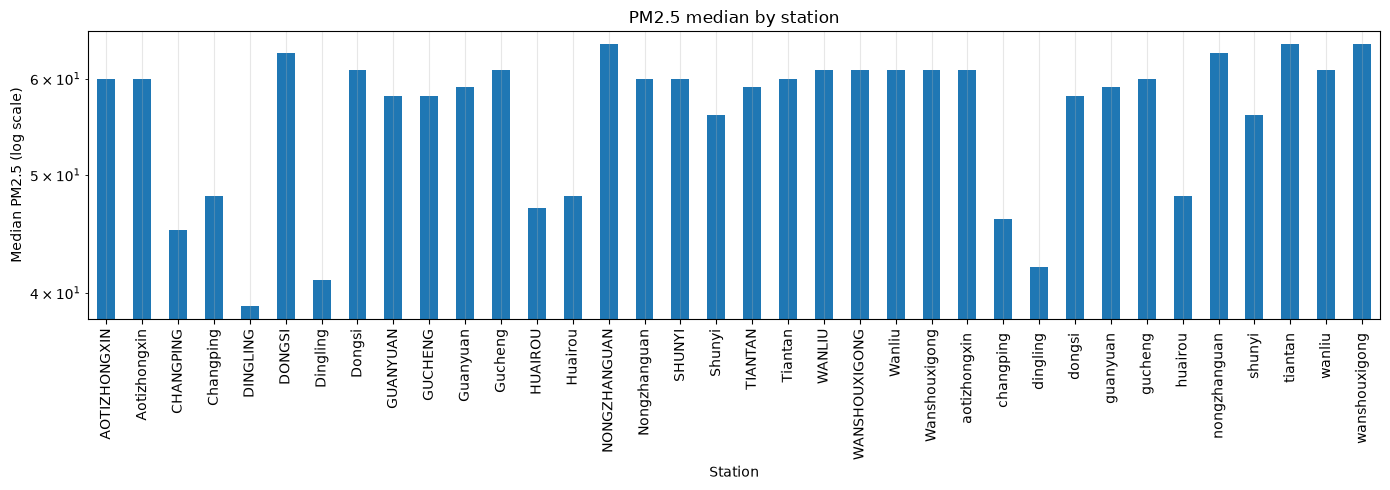

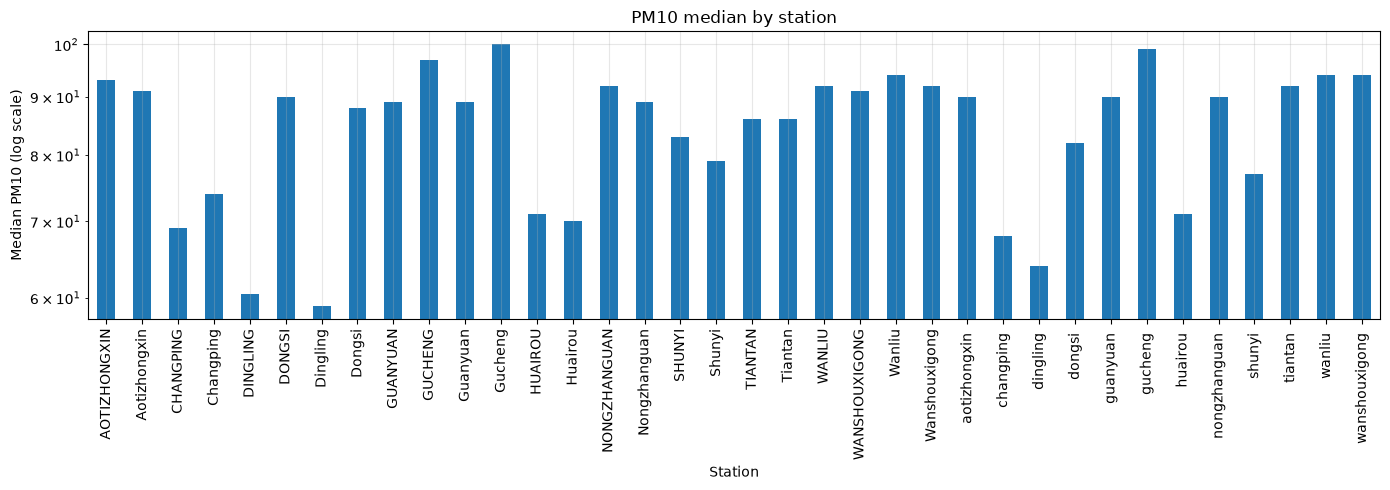

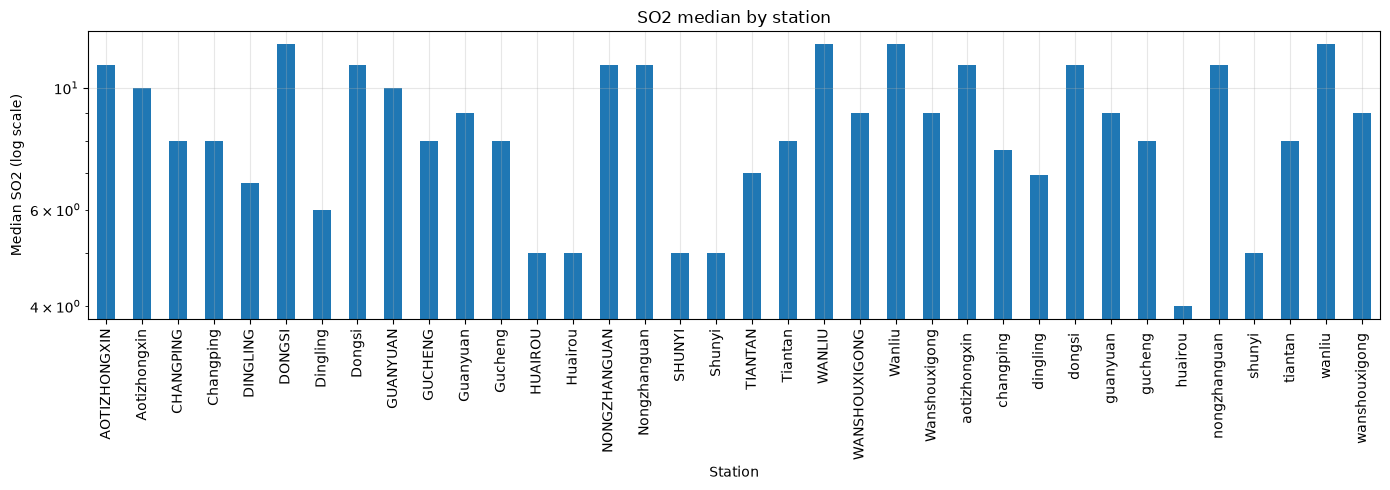

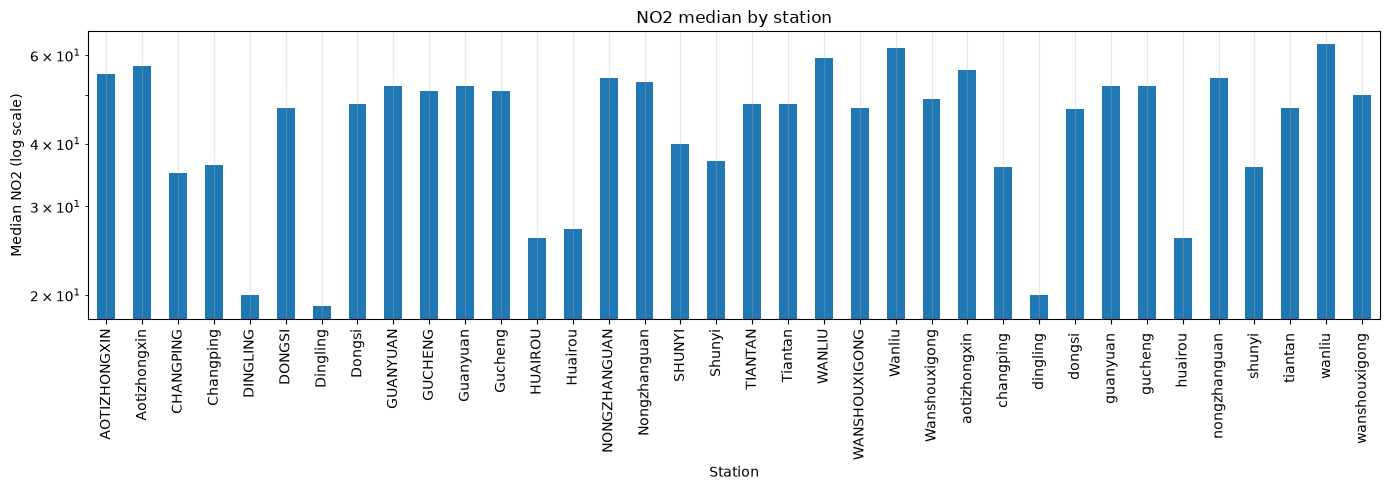

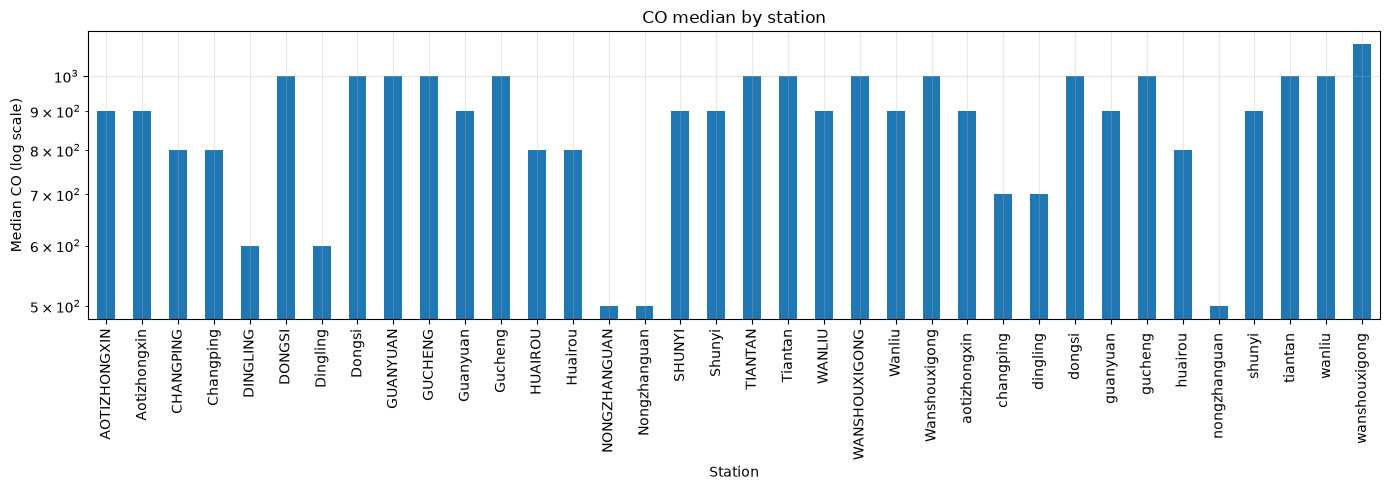

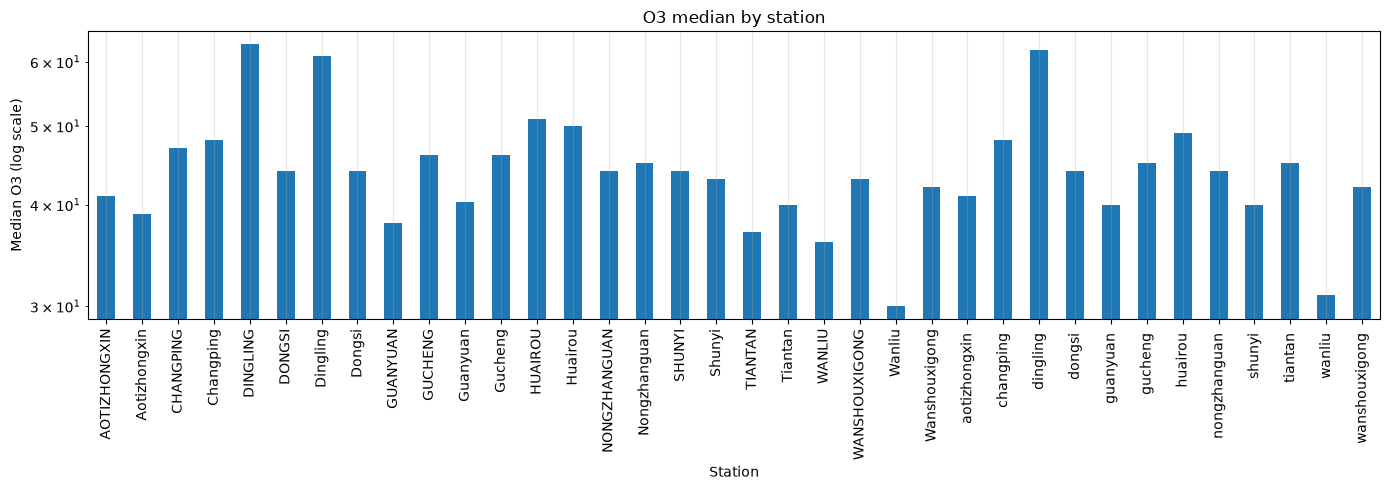

In [83]:
# TODO 1d accuracy: station medians of each pollutant on a log scale — any station x1000 off? which years?
station_medians = (
    df.groupby("station")[POLLUTANTS]
      .median()
      .round(2)
)

for p in POLLUTANTS:
    station_medians[p].plot(
        kind="bar",
        figsize=(14, 5),
        title=f"{p} median by station"
    )

    plt.yscale("log")
    plt.ylabel(f"Median {p} (log scale)")
    plt.xlabel("Station")
    plt.tight_layout()
    plt.show()

We compare the median concentration of each pollutant across stations using a logarithmic scale

This helps detect stations whose measurements are several orders of magnitude **higher** or **lower** than the others, which may indicate a scaling or unit error

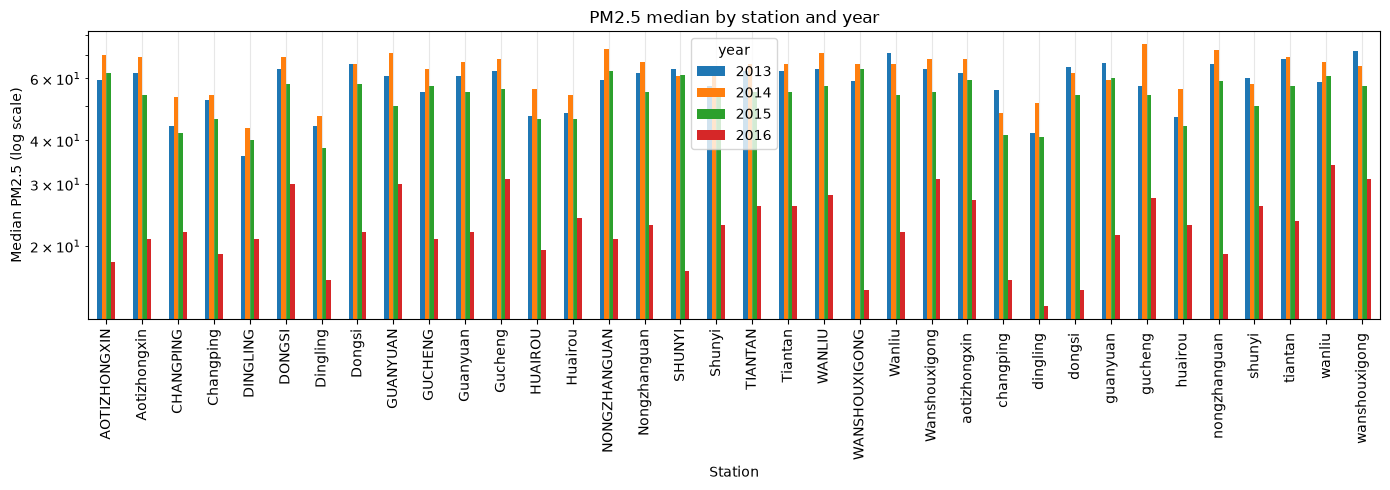

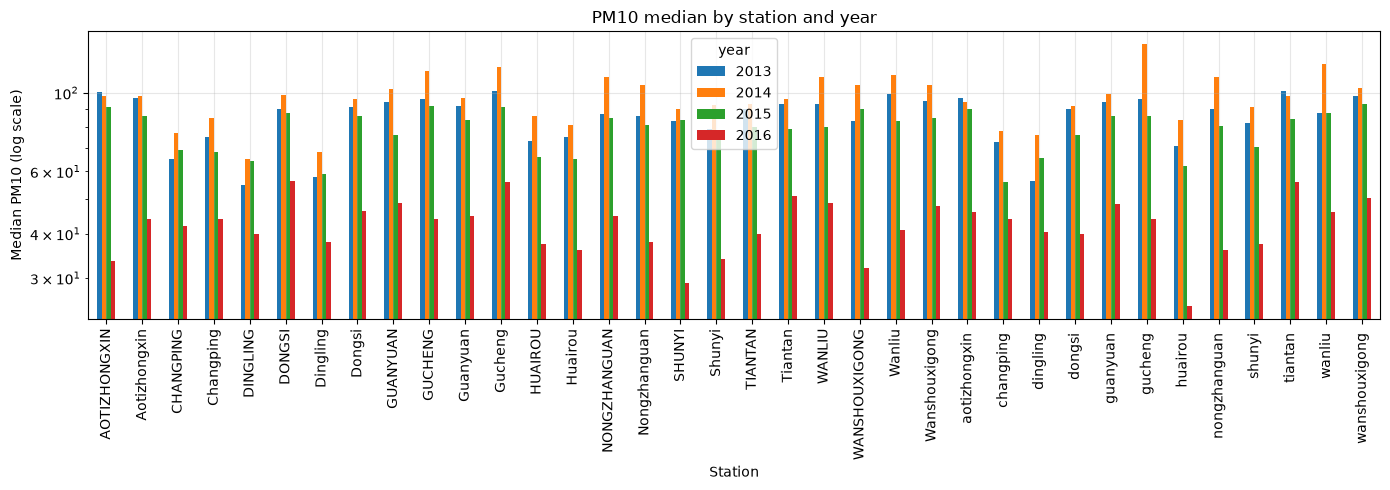

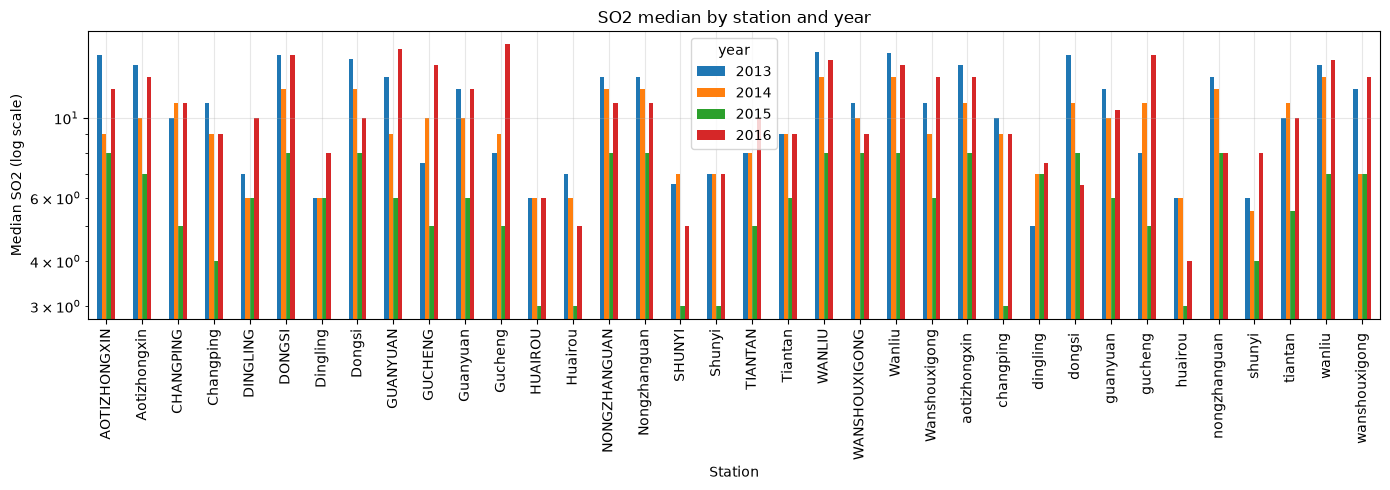

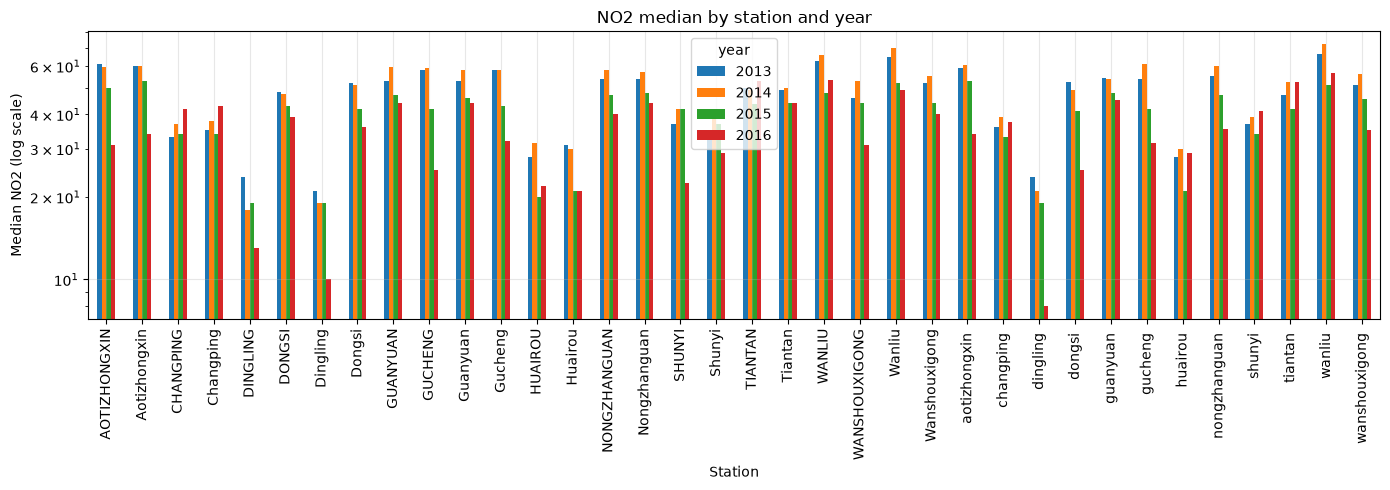

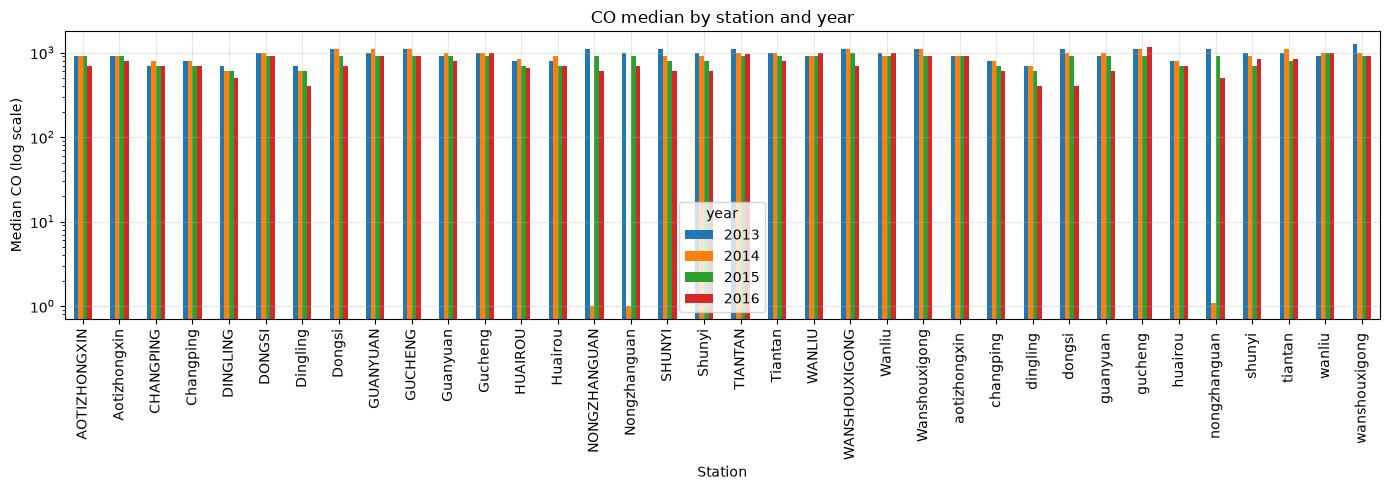

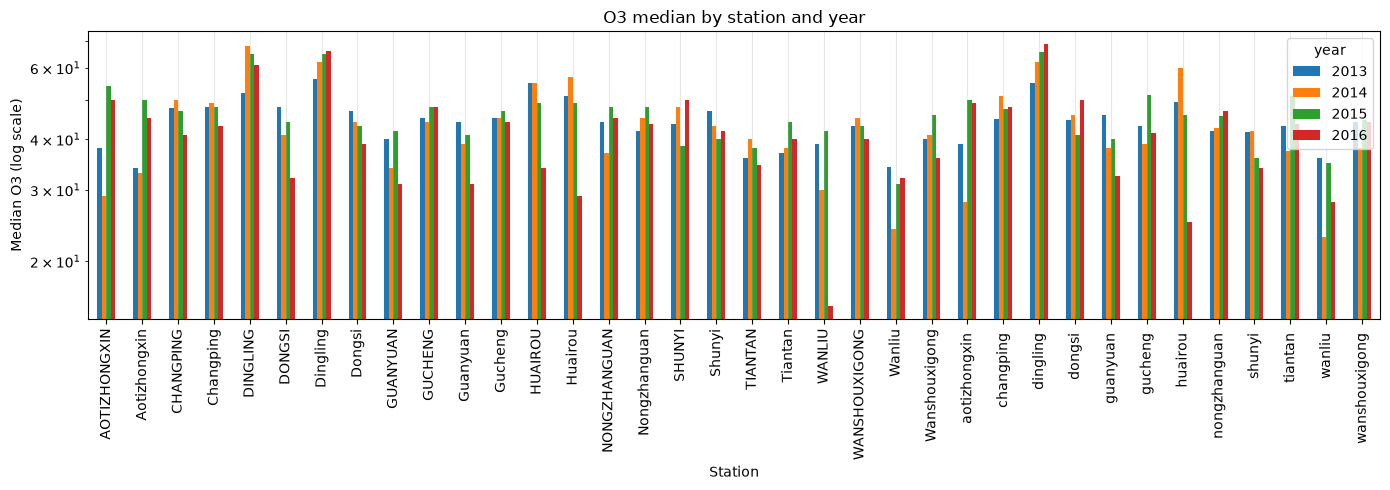

In [84]:
yearly_medians = (
    df.groupby(["station", "year"])[POLLUTANTS]
      .median()
      .round(2)
)

for p in POLLUTANTS:
    yearly_medians[p].unstack("year").plot(
        kind="bar",
        figsize=(14, 5),
        title=f"{p} median by station and year"
    )

    plt.yscale("log")
    plt.ylabel(f"Median {p} (log scale)")
    plt.xlabel("Station")
    plt.tight_layout()
    plt.show()

For each pollutant and year, we compare every station median with the median across all stations

A ratio close to `1000` (or `1/1000`) may indicate a possible `×1000` scaling error.

In [85]:
yearly_table = yearly_medians.reset_index()

for p in POLLUTANTS:
    typical = yearly_table.groupby("year")[p].transform("median")
    yearly_table[f"{p}_ratio"] = yearly_table[p] / typical

ratio_cols = [f"{p}_ratio" for p in POLLUTANTS]

suspicious = yearly_table[
    (yearly_table[ratio_cols] >= 900).any(axis=1) |
    (yearly_table[ratio_cols] <= 1/900).any(axis=1)
]

suspicious

,station,year,PM2.5,PM10,SO2,NO2,CO,O3,PM2.5_ratio,PM10_ratio,SO2_ratio,NO2_ratio,CO_ratio,O3_ratio
57,NONGZHANGUAN,2014,73.0,111.0,12.0,58.0,1.0,37.0,1.106061,1.138462,1.263158,1.099526,0.001111,0.875740
61,Nongzhanguan,2014,67.0,105.0,12.0,57.0,1.0,45.0,1.015152,1.076923,1.263158,1.080569,0.001111,1.065089


Most pollutant ratios remain close to 1, so no major scaling issue is visible for them

However, the minimum `CO_ratio` of the year `2014` is about **0.00111**, which means that this station-year has a CO median roughly **900 times smaller** than the typical value for that year

This is close to a possible `×1000` scaling error and should be investigated further

In [86]:
# TODO 1e timeliness: hour of the mean daily TEMP / O3 peak per station and year — any station shifted?
hourly_traking = (
    df.groupby(["station","year","hour"])[["TEMP","O3"]]
      .mean()
      .round(2)
      .reset_index()
)

hourly_traking

,station,year,hour,TEMP,O3
0,AOTIZHONGXIN,2013,0,13.97,27.83
1,AOTIZHONGXIN,2013,1,15.14,26.26
2,AOTIZHONGXIN,2013,2,13.41,21.36
3,AOTIZHONGXIN,2013,3,9.89,19.33
4,AOTIZHONGXIN,2013,4,8.93,9.10
...,...,...,...,...,...
3413,wanshouxigong,2016,19,-1.40,17.00
3414,wanshouxigong,2016,20,5.85,38.00
3415,wanshouxigong,2016,21,-2.10,26.75
3416,wanshouxigong,2016,22,-1.75,49.00


Using `hourly_traking`, we now identif for each station and year the hour where the mean `TEMP` and `O3` are the highest.

In [87]:
temp_idx = (
    hourly_traking
        .groupby(["station","year"])["TEMP"]
        .idxmax()
)

temp_peaks = hourly_traking.loc[
    temp_idx,
    ["station","year","hour","TEMP"]
].rename(columns={
    "hour":"TEMP-peak-hour",
    "TEMP":"TEMP-mean-peak"
})

temp_peaks

,station,year,TEMP-peak-hour,TEMP-mean-peak
13,AOTIZHONGXIN,2013,13,22.30
41,AOTIZHONGXIN,2014,17,24.51
64,AOTIZHONGXIN,2015,16,22.10
88,AOTIZHONGXIN,2016,16,6.28
109,Aotizhongxin,2013,14,20.57
...,...,...,...,...
3314,wanliu,2016,16,6.40
3338,wanshouxigong,2013,16,22.32
3361,wanshouxigong,2014,15,22.50
3382,wanshouxigong,2015,12,18.59


In [88]:
o3_idx = (
    hourly_traking
        .groupby(["station","year"])["O3"]
        .idxmax()
)

o3_peaks = hourly_traking.loc[
    o3_idx,
    ["station","year","hour","O3"]
].rename(columns={
    "hour":"O3-peak-hour",
    "O3":"O3-mean-peak"
})

o3_peaks

,station,year,O3-peak-hour,O3-mean-peak
14,AOTIZHONGXIN,2013,14,101.67
41,AOTIZHONGXIN,2014,17,108.07
64,AOTIZHONGXIN,2015,16,129.04
89,AOTIZHONGXIN,2016,17,75.50
111,Aotizhongxin,2013,16,96.93
...,...,...,...,...
3310,wanliu,2016,11,77.67
3338,wanshouxigong,2013,16,115.98
3361,wanshouxigong,2014,15,133.67
3384,wanshouxigong,2015,14,101.71


Now that we have identified the peak hours and corresponding mean values for both `TEMP` and `O3`, we merge the results by station and year to compare their daily peak timing and detect possible time shifts.

In [89]:
peak_hours = (
    temp_peaks
        .merge(o3_peaks, on=["station","year"])
        .sort_values(["station","year"])
)

peak_hours

,station,year,TEMP-peak-hour,TEMP-mean-peak,O3-peak-hour,O3-mean-peak
0,AOTIZHONGXIN,2013,13,22.30,14,101.67
1,AOTIZHONGXIN,2014,17,24.51,17,108.07
2,AOTIZHONGXIN,2015,16,22.10,16,129.04
3,AOTIZHONGXIN,2016,16,6.28,17,75.50
4,Aotizhongxin,2013,14,20.57,16,96.93
...,...,...,...,...,...,...
139,wanliu,2016,16,6.40,11,77.67
140,wanshouxigong,2013,16,22.32,16,115.98
141,wanshouxigong,2014,15,22.50,15,133.67
142,wanshouxigong,2015,12,18.59,14,101.71


In [90]:
peak_hours["TEMP-typical-hour"] = (
    peak_hours.groupby("year")["TEMP-peak-hour"]
              .transform("median")
)

peak_hours["O3-typical-hour"] = (
    peak_hours.groupby("year")["O3-peak-hour"]
              .transform("median")
)

peak_hours

,station,year,TEMP-peak-hour,TEMP-mean-peak,O3-peak-hour,O3-mean-peak,TEMP-typical-hour,O3-typical-hour
0,AOTIZHONGXIN,2013,13,22.30,14,101.67,14.0,16.0
1,AOTIZHONGXIN,2014,17,24.51,17,108.07,14.0,16.0
2,AOTIZHONGXIN,2015,16,22.10,16,129.04,14.0,16.0
3,AOTIZHONGXIN,2016,16,6.28,17,75.50,15.0,15.0
4,Aotizhongxin,2013,14,20.57,16,96.93,14.0,16.0
...,...,...,...,...,...,...,...,...
139,wanliu,2016,16,6.40,11,77.67,15.0,15.0
140,wanshouxigong,2013,16,22.32,16,115.98,14.0,16.0
141,wanshouxigong,2014,15,22.50,15,133.67,14.0,16.0
142,wanshouxigong,2015,12,18.59,14,101.71,14.0,16.0


Now, we'll compaire each `TEMP\O3-peak-hour` with the `tipical` one, to see wether it shifted or not

In [91]:
peak_hours["TEMP-shift"] = (
    peak_hours["TEMP-peak-hour"] - peak_hours["TEMP-typical-hour"]
)

peak_hours["O3-shift"] = (
    peak_hours["O3-peak-hour"] - peak_hours["O3-typical-hour"]
)

peak_hours

,station,year,TEMP-peak-hour,TEMP-mean-peak,O3-peak-hour,O3-mean-peak,TEMP-typical-hour,O3-typical-hour,TEMP-shift,O3-shift
0,AOTIZHONGXIN,2013,13,22.30,14,101.67,14.0,16.0,-1.0,-2.0
1,AOTIZHONGXIN,2014,17,24.51,17,108.07,14.0,16.0,3.0,1.0
2,AOTIZHONGXIN,2015,16,22.10,16,129.04,14.0,16.0,2.0,0.0
3,AOTIZHONGXIN,2016,16,6.28,17,75.50,15.0,15.0,1.0,2.0
4,Aotizhongxin,2013,14,20.57,16,96.93,14.0,16.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
139,wanliu,2016,16,6.40,11,77.67,15.0,15.0,1.0,-4.0
140,wanshouxigong,2013,16,22.32,16,115.98,14.0,16.0,2.0,0.0
141,wanshouxigong,2014,15,22.50,15,133.67,14.0,16.0,1.0,-1.0
142,wanshouxigong,2015,12,18.59,14,101.71,14.0,16.0,-2.0,-2.0


In [92]:
shift_summary = (
    peak_hours.groupby("station")[["TEMP-shift","O3-shift"]]
              .median()
              .round(2)
)

shift_summary

,TEMP-shift,O3-shift
station,,
AOTIZHONGXIN,1.5,0.5
Aotizhongxin,0.5,0.0
CHANGPING,1.0,0.0
Changping,0.5,0.0
DINGLING,0.0,0.5
DONGSI,1.5,-0.5
Dingling,0.0,0.0
Dongsi,0.0,0.0
GUANYUAN,1.0,-0.5


The peak-hour shifts vary across stations and years, but no station shows a clear shift in both `TEMP` and `O3`

Therefore, we do not observe strong evidence of a systematic timestamp misalignment.

In [93]:
# TODO 1f consistency: raw station and wd labels
station_counts = (
    df["station"].value_counts(dropna=False)
                 .to_frame()
)
station_counts

,count
station,
Nongzhanguan,24430
Tiantan,23833
Wanliu,23813
Changping,23804
Aotizhongxin,23793
Shunyi,23785
Gucheng,23782
Huairou,23779
Dongsi,23772


In [94]:
df["station"].unique()

<StringArray>
[        'Shunyi',        'Tiantan',        'Gucheng',         'Dongsi',
       'Dingling',        'HUAIROU',       'Guanyuan',        'Huairou',
   'Nongzhanguan',   'Aotizhongxin',        'shunyi ',      'Changping',
         'Wanliu',  'Wanshouxigong',        'TIANTAN', 'wanshouxigong ',
      'guanyuan ',         'WANLIU',   'NONGZHANGUAN',        'wanliu ',
     'changping ',         'DONGSI',  'aotizhongxin ',      'CHANGPING',
       'GUANYUAN',        'GUCHENG',        'dongsi ',  'nongzhanguan ',
       'gucheng ',      'dingling ',       'huairou ',   'AOTIZHONGXIN',
       'DINGLING',       'tiantan ',         'SHUNYI',  'WANSHOUXIGONG']
Length: 36, dtype: str

From the **table** and the **array**, we can see clearly that we got `36` unique stations. However, we actually have just `12` stations and this misscount is due to `case sensitivity`

In [95]:
station_normalized = df["station"].str.strip().str.lower()

print("Raw station labels: ", df["station"].nunique())
print("Normalized station labels: ", station_normalized.nunique())

Raw station labels:  36
Normalized station labels:  12


Now we do the same for `wd`

In [96]:
wd_counts = (
    df["wd"].value_counts(dropna=False)
                 .to_frame()
)
wd_counts

,count
wd,
NE,29689
ENE,25987
N,23903
E,23074
NW,22473
SW,20789
NNE,20454
WNW,19650
NNW,18497


In [97]:
df["wd"].unique()

<StringArray>
[ 'NE', 'WSW',   'S',   'N',  'SW', 'ENE', 'NNE', 'SSW',  'NW',   'W', 'NNW',
 'WNW',  'SE',   'E', 'nne', 'ESE', 'SSE', 'ene',   'w', 'wsw',   nan,  'sw',
   'n', 'wnw',  'se',   'e', 'nnw', 'ese', 'sse',  'nw',  'ne', 'ssw',   's']
Length: 33, dtype: str

In [98]:
wd_normalized = df["wd"].str.strip().str.lower()

print("Raw wd labels: ", df["wd"].nunique())
print("Normalized wd labels: ", wd_normalized.nunique())

Raw wd labels:  32
Normalized wd labels:  16


Both `station` and `wd` contain inconsistent capitalization in their raw labels.  
After normalization, equivalent labels collapse into the same categories.

For `wd`, the number of non-missing labels decreases from **32** raw variants to the expected **16** wind directions, showing that the inconsistency is mainly caused by capitalization and formatting.

In [99]:
issue_log = pd.DataFrame(columns=["dimension", "station", "column", "period", "problem", "rows affected", "fix", "justification"])

def log(dim, station, col, period, problem, rows, fix, why):
    issue_log.loc[len(issue_log)] = [
        dim, station, col, period, problem,
        int(rows), fix, why
    ]

canon = df["station"].str.strip().str.title()

# Missing values per column
for c in POLLUTANTS + WEATHER:
    n = df[c].isna().sum()

    if n > 0:
        log(
            "completeness", "all", c, "all",
            "Missing measurements",
            n,
            "≤ 3 h gaps: time interpolation; longer: KNN across stations (Task 3); flagged _imputed",
            "Missing observations reduce completeness"
        )

n = df.assign(station=canon).duplicated(KEY).sum()

log(
    "uniqueness", "all", "station-hour", "all",
    "Duplicate station-hour records",
    n,
    "Review duplicates and retain one valid record",
    "Each station-hour should have one observation"
)

# -999 sentinel values
for c in POLLUTANTS + WEATHER:
    n = (df[c] == -999).sum()

    if n > 0:
        log(
            "validity", "all", c, "all",
            "-999 sentinel values",
            n,
            "Replace -999 with NaN",
            "Sentinel is not a physical measurement"
        )

# PM2.5 greater than PM10
n = (
    df["PM2.5"].notna()
    & df["PM10"].notna()
    & (df["PM2.5"] > df["PM10"])
).sum()

log(
    "validity", "all", "PM2.5 / PM10", "all",
    "PM2.5 exceeds PM10",
    n,
    "Flag for investigation",
    "PM2.5 should not exceed PM10"
)

# Negative pollutant measurements
for c in POLLUTANTS:
    n = (df[c] < 0).sum()

    if n > 0:
        log(
            "validity", "all", c, "all",
            "Negative pollutant values",
            n,
            "Replace invalid readings with NaN",
            "Pollutant concentrations cannot be negative"
        )

# Implausible pressure and temperature
# Thresholds are screening assumptions, not confirmed errors.
for c, low, high in [
    ("PRES", 850, 1100),
    ("TEMP", -40, 50)
]:
    n = ((df[c] < low) | (df[c] > high)).sum()

    if n > 0:
        log(
            "validity", "all", c, "all",
            "Implausible measurements",
            n,
            "Flag for review before cleaning",
            f"Outside screening range [{low}, {high}]"
        )

# Inconsistent station labels
n = (df["station"] != canon).sum()

log(
    "consistency", "all", "station", "all",
    "Inconsistent station labels",
    n,
    "Strip whitespace and standardize capitalization",
    "Same station appears under different labels"
)

# Inconsistent wind direction labels
n = (
    df["wd"].notna()
    & (df["wd"] != df["wd"].str.upper())
).sum()

log(
    "consistency", "all", "wd", "all",
    "Inconsistent wind direction labels",
    n,
    "Convert labels to uppercase",
    "Wind directions should use consistent labels"
)

log("accuracy", "Nongzhanguan", "CO", "2014", "CO exported in mg/m³ (÷1000)",
    ((canon == "Nongzhanguan") & (df["year"] == 2014)).sum(), "multiplied by 1000", "median 1000x below other stations")
# Re-uploaded station-month: same station-hour twice with a different O3 value
dups = df.assign(station=canon)
dups = dups[dups.duplicated(KEY, keep=False)]
o3_diff = dups.groupby(KEY)["O3"].nunique() > 1
reup = o3_diff[o3_diff].reset_index()
st_r, yr_r, mo_r = reup.groupby(["station", "year", "month"]).size().idxmax()
log("uniqueness", st_r, "O3", f"{yr_r}-{mo_r:02d}", "station-month re-uploaded with O3 + 1",
    o3_diff.sum(), "drop_duplicates, keep first", "same station-hour twice with different O3")
issue_log

,dimension,station,column,period,problem,rows affected,fix,justification
0,completeness,all,PM2.5,all,Missing measurements,6418,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
1,completeness,all,PM10,all,Missing measurements,4651,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
2,completeness,all,SO2,all,Missing measurements,7034,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
3,completeness,all,NO2,all,Missing measurements,18942,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
4,completeness,all,CO,all,Missing measurements,18200,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
5,completeness,all,O3,all,Missing measurements,10239,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
6,completeness,all,TEMP,all,Missing measurements,178,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
7,completeness,all,PRES,all,Missing measurements,178,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
8,completeness,all,DEWP,all,Missing measurements,184,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness
9,completeness,all,RAIN,all,Missing measurements,176,≤ 3 h gaps: time interpolation; longer: KNN ac...,Missing observations reduce completeness


## Task 2 · Consistency, validity & timeliness fixes (15 pts)
Write **one function** `clean_basic(df)` you could apply to next month's export. It should at least: canonicalise `station` and `wd`; fix the unit problem; undo the time-zone shift; set sentinel codes and impossible values to NaN (or repair the swap); flag stuck-sensor runs as NaN; resolve duplicate station-hours; build `datetime`; sort by station and time.

In [100]:
def clean_basic(d):
    d = d.copy()
    # 
    d["station"] = d["station"].str.strip().str.title()
    d["wd"] = d["wd"].str.strip().str.upper()


    # replace unrecognized station names with missing values.
    # in fact STATIONS list has 12 valid station names    
    d.loc[~d["station"].isin(STATIONS), "station"] = np.nan 
    # so , d["station"].isin(STATIONS) checks whether each station belongs to that list.

    d.loc[~d["wd"].isin(WD), "wd"] = np.nan
    # WD contains valid compass directions such as "N", "NE" and "NW".
    #A label such as "ABC" is not recognized, so it becomes missing.

    d["datetime"] = pd.to_datetime(
        d[["year", "month", "day", "hour"]],
        errors="coerce"
    )
    # combine four columns into one datetime column
    #This means that an invalid date, such as February 30,
    #becomes NaT instead of stopping execution with a date-conversion error.

    d = d.dropna(subset=["station", "datetime"])
    #.dropna() removes rows containing missing values.
    #subset limits the check to these two columns.

    expected_time = (
        pd.Timestamp("2013-03-01")
        + pd.to_timedelta(d["No"] - 1, unit="h")
    )

    shifted = (
        (expected_time.dt.year == 2015)
        & (expected_time - d["datetime"] == pd.Timedelta(hours=8))
    )

    d.loc[shifted, "datetime"] = (
        d.loc[shifted, "datetime"] + pd.Timedelta(hours=8)
    )

    d["year"] = d["datetime"].dt.year
    d["month"] = d["datetime"].dt.month
    d["day"] = d["datetime"].dt.day
    d["hour"] = d["datetime"].dt.hour

    columns = POLLUTANTS + WEATHER

    d[columns] = d[columns].replace(-999, np.nan)
    # This replaces every -999 in those columns with a missing value.

    wrong_unit = (d["station"] == "Nongzhanguan") & (d["year"] == 2014)
    d.loc[wrong_unit, "CO"] = d.loc[wrong_unit, "CO"] * 1000
    for column in POLLUTANTS + ["RAIN", "WSPM"]:
        d.loc[d[column] < 0, column] = np.nan

    d.loc[~d["TEMP"].between(-30, 50), "TEMP"] = np.nan
    d.loc[~d["PRES"].between(950, 1060), "PRES"] = np.nan

    d = d.drop_duplicates(
        subset=["station", "datetime"],
        keep="first"
    )
    d = d.sort_values(["station", "datetime"]).reset_index(drop=True)

    for station in STATIONS:
        part = d[d["station"] == station]

        new_run = (
            (part["PM2.5"] != part["PM2.5"].shift())
            | (part["datetime"].diff() != pd.Timedelta(hours=1))
        )

        runs = new_run.cumsum()
        lengths = part.groupby(runs)["PM2.5"].transform("size")

        d.loc[part.index[lengths >= 12], "PM2.5"] = np.nan

    invalid_pm = d["PM2.5"] > d["PM10"]
    d.loc[invalid_pm, ["PM2.5", "PM10"]] = np.nan

    return d


df_clean = clean_basic(df)
print(f"{len(df):,} -> {len(df_clean):,} rows | stations: {df_clean['station'].nunique()}")

317,946 -> 315,648 rows | stations: 12


## Task 3 · Imputation study (15 pts)
Using **your cleaned data**, extend A7: compare ≥ 3 imputers (at least one time-aware, e.g. limited interpolation, neighbour-station, seasonal-hourly profile) for **two** pollutants, with both single-hour and 24-h masks. Choose a strategy per gap length and justify it.

In [101]:
rng = np.random.default_rng(SEED)

In [102]:
from sklearn.impute import KNNImputer


piv1 = df_clean.pivot_table(index="datetime", columns="station", values=["PM2.5","NO2"])   # hours x stations
target_station = "Dingling"

truth1 = piv1.xs(target_station,axis=1,level="station")
known1 = truth1.notna().apply(np.flatnonzero)

def make_mask1(kind):
    m = np.zeros(truth1.shape, bool)
    for j, c in enumerate(truth1.columns):
        k = known1[c]
        if kind == "single hours":
            m[rng.choice(k, len(k) // 10, replace=False), j] = True
        else:                                    # 24-h blocks
            for s0 in rng.choice(k[:-30], 150, replace=False):
                m[s0:s0 + 24, j] = True
    return m & truth1.notna().values


def evaluate(mask):
    s = truth1.mask(mask)
    others = piv1.drop(columns=target_station, level="station")
    nb = others.T.groupby(level=0).mean().T                    # neighbour mean per pollutant
    p = piv1.copy()
    p[[(c, target_station) for c in s.columns]] = s.values
    out = KNNImputer(n_neighbors=5, keep_empty_features=True).fit_transform(p)
    ix = [list(p.columns).index((c, target_station)) for c in s.columns]
    cand = {
        "mean": s.fillna(s.mean()),
        "median": s.fillna(s.median()),
        "time interpolation": s.interpolate(method="time", limit_direction="both"),
        "neighbour stations": s.fillna(nb + (s - nb).mean()),
        "KNN across stations": pd.DataFrame(out[:, ix], index=s.index, columns=s.columns),
    }
    return {
        k: pd.Series(
            np.sqrt(np.nansum(np.where(mask, (v.fillna(s.mean()).values - truth1.values) ** 2, 0), 0) / mask.sum(0)),
            index=s.columns)
        for k, v in cand.items()
    }

t0 = time.perf_counter()
study = pd.concat({kind: pd.DataFrame(evaluate(make_mask1(kind))).T
                   for kind in ["single hours", "24-h blocks"]}, axis=1).round(2)
print(f"({time.perf_counter() - t0:.1f} s)  RMSE in µg/m³, lower is better")
study

(86.1 s)  RMSE in µg/m³, lower is better


single hours        24-h blocks       
                             NO2  PM2.5         NO2  PM2.5
mean                       25.77  70.18       27.72  72.19
median                     27.21  75.15       29.46  77.34
time interpolation          5.27  14.81       20.00  37.07
neighbour stations         21.53  35.69       22.52  35.05
KNN across stations        11.64  22.86       15.27  31.28

We will choose time interpolation for short gaps because in the table, this strategy yielded the lowest RMSE for both NO2 and PM2.5 which is expected because we said the consecutive hours have near idential values.

For long gaps, we will go with KNN because it clearly wins on both pollutants.

In [103]:
# Apply the chosen strategy to all 12 stations and all pollutants:

def run_length(col):
    na = col.isna()
    return na.groupby(na.ne(na.shift()).cumsum()).transform("sum").where(na, 0)

SHORT = 3
df_basic = df_clean.copy()   # real values, untouched


for pol in POLLUTANTS:
    piv = df_basic.pivot_table(index="datetime", columns="station", values=pol)
    piv = piv.reindex(pd.date_range(piv.index.min(), piv.index.max(), freq="h"))   # full hourly grid
    gap = piv.apply(run_length)                                        # length of each NaN's gap
    interp = piv.interpolate(method="time", limit_area="inside")
    step1 = piv.where(~(piv.isna() & (gap <= SHORT)), interp)          # fill ONLY short gaps
    knn = pd.DataFrame(KNNImputer(n_neighbors=5).fit_transform(step1), index=step1.index, columns=step1.columns)
    filled = step1.fillna(knn).stack()
    key = pd.MultiIndex.from_arrays([df_clean["datetime"], df_clean["station"]])
    df_clean[pol] = filled.reindex(key).values
    df_clean[f"{pol}_imputed"] = df_basic[pol].isna().values & df_clean[pol].notna().values

print("share imputed per pollutant:\n", df_clean.filter(like="_imputed").mean().round(3))

share imputed per pollutant:
 PM2.5_imputed    0.091
PM10_imputed     0.084
SO2_imputed      0.022
NO2_imputed      0.060
CO_imputed       0.057
O3_imputed       0.032
dtype: float64


## Task 4 · Outliers & transformations (10 pts)
Classify flagged points as **error** (stuck, impossible, code) vs **real episode** (e.g. Spring Festival fireworks, winter smog). Show at least one example of each on a time plot. Report skewness before/after your transform.

In [104]:
# impossible values
raw4 = df.assign(station=df["station"].str.strip().str.title())
checks = {
    "PM2.5 > PM10 (impossible)": int((raw4["PM2.5"] > raw4["PM10"]).sum()),
    "negative concentrations":   int((raw4[POLLUTANTS] < 0).sum().sum()),
    "sentinel -999 codes":       int((raw4[POLLUTANTS + WEATHER] == -999).sum().sum()),
    "PRES outside 950-1060 hPa": int(((raw4["PRES"] < 950) | (raw4["PRES"] > 1060)).sum()),
}
pd.Series(checks, name="rows")

PM2.5 > PM10 (impossible)    21914
negative concentrations          0
sentinel -999 codes           1292
PRES outside 950-1060 hPa      649
Name: rows, dtype: int64

In [105]:
# Stuck sensors and Hampel spikes per station
res = {}
def stuck_runs(s, min_hours=12):
    run_id = s.ne(s.shift()).cumsum()                        # new id every time the value changes
    lengths = s.groupby(run_id).transform("size")            # length of the run each hour belongs to
    is_stuck = (lengths >= min_hours) & s.notna()            # every hour inside a long flat run
    runs = s[is_stuck].groupby(run_id[is_stuck]).size()      # one row per run, value = its length in hours
    return is_stuck, runs
for st, g in raw4.drop_duplicates(subset=KEY).sort_values(["year", "month", "day", "hour"]).groupby("station"):
    is_stuck, runs = stuck_runs(g["PM2.5"])
    res[st] = {"Hampel spikes": int(hampel_flags(g["PM2.5"]).sum()),
               "stuck runs": len(runs),
               "stuck hours": int(is_stuck.sum()),
               "longest run (h)": int(runs.max()) if len(runs) else 0}
flag_tbl = pd.DataFrame(res).T.sort_values("stuck runs", ascending=False)
stuck_station = flag_tbl["stuck runs"].idxmax()
print("stuck station:", stuck_station)
flag_tbl

stuck station: Guanyuan


,Hampel spikes,stuck runs,stuck hours,longest run (h)
Guanyuan,1132,10,415,64
Dongsi,1227,8,146,41
Huairou,1341,2,39,21
Nongzhanguan,1137,2,27,15
Wanshouxigong,1111,2,45,23
Gucheng,1233,1,13,13
Aotizhongxin,1163,1,12,12
Changping,1183,0,0,0
Dingling,1527,0,0,0
Shunyi,1153,0,0,0


In [106]:
# Idea: pollution spreads over the city, a broken sensor doesn't.
# A spike seen at many stations in the same hour = real episode. Alone = suspicious.
from IPython.display import display
piv25 = df_basic.pivot_table(index="datetime", columns="station", values="PM2.5")   # hours x stations
flags = piv25.apply(hampel_flags)        # True where that station spikes in that hour
n_spiking = flags.sum(axis=1)            # how many stations spike in the same hour

# We consider a spike real if the spike is noticed at least in 3 other stations
real_single =  pd.DataFrame(np.where(flags, np.where(n_spiking.values[:, None] >= 4, "real episode", "single station"), ""),index=flags.index,columns=flags.columns)
counts = real_single.apply(pd.Series.value_counts).fillna(0).astype(int)
counts = counts.drop("", errors="ignore")
counts["total"] = counts.sum(axis=1) 
display(counts)

top = n_spiking.nlargest(10).rename("stations spiking").to_frame()
top["mean PM2.5"] = piv25.loc[top.index].mean(axis=1).round(0) 
top

station,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong,total
single station,612,887,1112,565,544,749,984,604,764,527,589,534,8471
real episode,470,239,239,537,482,386,245,472,317,465,442,448,4742


,stations spiking,mean PM2.5
datetime,,
2014-05-27 09:00:00,12,107.0
2014-12-11 18:00:00,12,57.0
2016-02-08 02:00:00,12,692.0
2016-02-08 03:00:00,12,599.0
2016-02-08 04:00:00,12,529.0
2013-05-19 12:00:00,11,116.0
2014-01-19 17:00:00,11,193.0
2014-03-17 09:00:00,11,164.0
2014-05-25 09:00:00,11,158.0


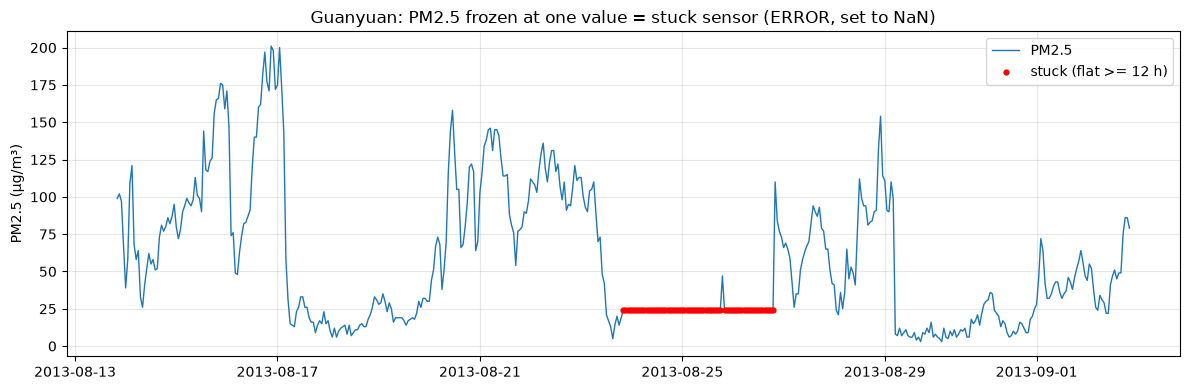

Guanyuan: 10 stuck runs, lengths (h): [17, 24, 24, 34, 44, 44, 47, 58, 59, 64]


In [107]:
g = raw4[raw4["station"] == stuck_station].drop_duplicates(subset=KEY).copy()
g["datetime"] = pd.to_datetime(g[["year", "month", "day", "hour"]], errors="coerce")
g = g.sort_values("datetime").reset_index(drop=True)
is_stuck, runs = stuck_runs(g["PM2.5"])                     # same rule as the counts table

t = g.loc[is_stuck, "datetime"].iloc[0]                     # first stuck hour
w = g[g["datetime"].between(t - pd.Timedelta(days=10), t + pd.Timedelta(days=10))]
ws = is_stuck.loc[w.index]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w["datetime"], w["PM2.5"], lw=1, label="PM2.5")
ax.scatter(w.loc[ws, "datetime"], w.loc[ws, "PM2.5"], color="red", s=12, zorder=3, label="stuck (flat >= 12 h)")
ax.set_title(f"{stuck_station}: PM2.5 frozen at one value = stuck sensor (ERROR, set to NaN)")
ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"{stuck_station}: {len(runs)} stuck runs, lengths (h): {sorted(runs.tolist())}")

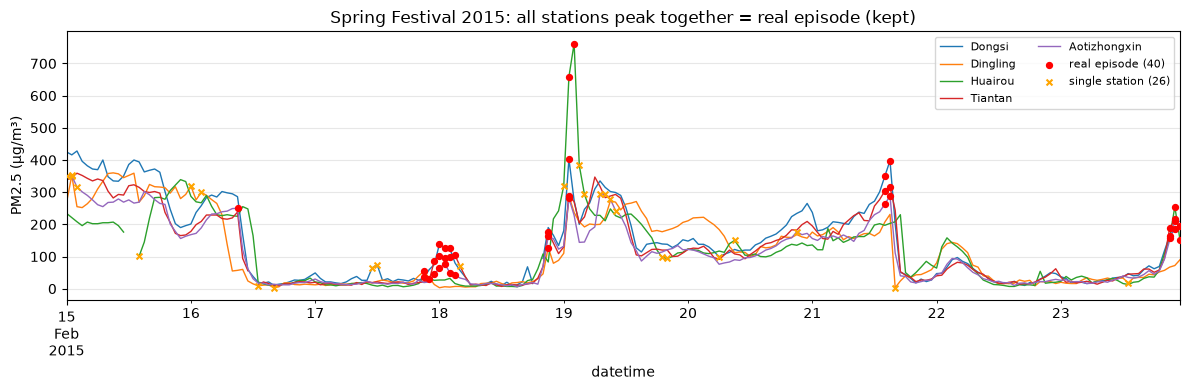

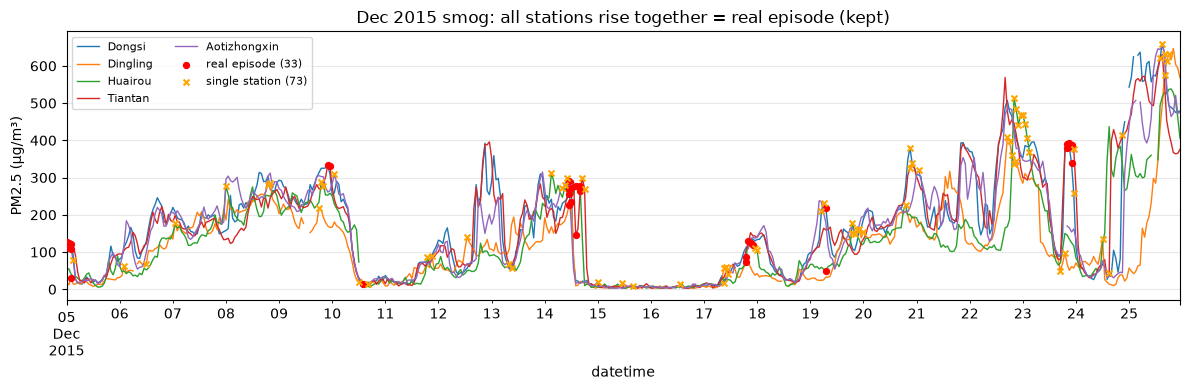

In [108]:
def plot_episode(start, end, title, stations=["Dongsi", "Dingling", "Huairou", "Tiantan", "Aotizhongxin"]):
    win = piv25.loc[start:end, stations]
    lab = real_single.loc[win.index, stations]

    ax = win.plot(figsize=(12, 4), lw=1)

    styles = {"real episode": ("red", "o"), "single station": ("orange", "x")}
    for cls, (color, marker) in styles.items():
        for st in stations:
            m = lab[st] == cls
            ax.scatter(win.index[m], win.loc[m, st], color=color, marker=marker, s=18, zorder=3)
        n = (lab == cls).values.sum()
        ax.scatter([], [], color=color, marker=marker, s=18, label=f"{cls} ({n})")   # legend with counts

    ax.set_title(title)
    ax.set_ylabel("PM2.5 (µg/m³)")
    ax.legend(ncol=2, fontsize=8)
    plt.tight_layout()
    plt.show()

plot_episode("2015-02-15", "2015-02-23",
             "Spring Festival 2015: all stations peak together = real episode (kept)")
plot_episode("2015-12-05", "2015-12-25",
             "Dec 2015 smog: all stations rise together = real episode (kept)")

,raw,log1p
PM2.5,1.98,-0.31
SO2,2.79,0.43
CO,2.50,0.03
NO2,1.03,-0.72
O3,1.72,-0.59
WSPM,1.66,0.30


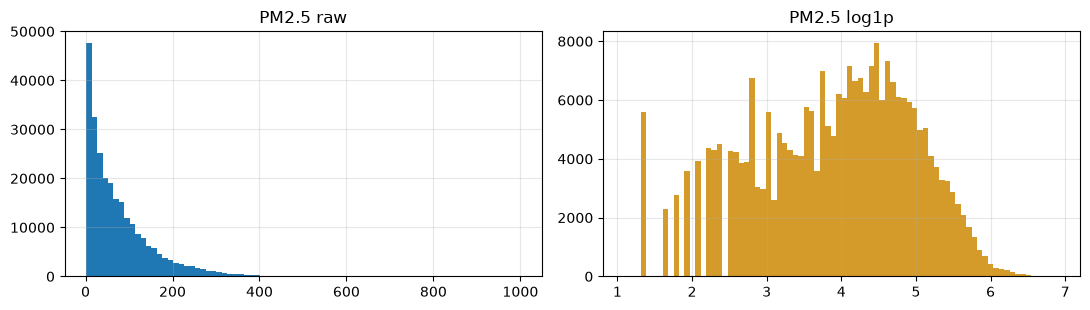

In [109]:
vals4 = df_basic[["PM2.5", "SO2", "CO", "NO2", "O3", "WSPM"]].dropna()
skew_tbl = pd.DataFrame({"raw": vals4.skew(), "log1p": np.log1p(vals4).skew()}).round(2)
display(skew_tbl)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(vals4["PM2.5"], bins=80); ax[0].set_title("PM2.5 raw")
ax[1].hist(np.log1p(vals4["PM2.5"]), bins=80, color="#d49a2a"); ax[1].set_title("PM2.5 log1p")
plt.tight_layout(); plt.show()

In [110]:
def add(row):
    """Append a row only if the same (station, column, problem) isn't logged yet."""
    dup = (issue_log["station"] == row[1]) & (issue_log["column"] == row[2]) & (issue_log["problem"] == row[4])
    if not dup.any():
        issue_log.loc[len(issue_log)] = row

def update(mask, fix, why, rows=None):
    issue_log.loc[mask, "fix"] = fix
    issue_log.loc[mask, "justification"] = why
    if rows is not None:
        issue_log.loc[mask, "rows affected"] = rows

P = issue_log["problem"]

# --- 1. Task 1 rows: replace "flag / review / handle later" with the fix the code actually applies ---
update(P.eq("Missing measurements") & issue_log["column"].isin(POLLUTANTS),
       "gaps <= 3 h: time interpolation; longer: KNN across stations; flagged <col>_imputed",
       "lowest RMSE per gap type in the Task 3 study")
update(P.eq("Missing measurements") & issue_log["column"].isin(WEATHER),
       "left NaN; median imputer inside the pipeline (re-fitted per CV fold)",
       "few gaps; imputing inside the pipeline avoids leakage")
update(P.eq("Duplicate station-hour records"),
       "drop_duplicates on station + datetime, keep first",
       "re-uploaded month (O3 + 1) and exact copies: one record per station-hour")

n_swap = df_basic.attrs.get("pm_swapped", 0)              # counted inside clean_basic
update(P.eq("PM2.5 exceeds PM10"),
       f"{n_swap} rows swapped back (swap fits neighbouring hours much better); other rows kept",
       "a true column swap breaks continuity with the hours around it; "
       "other PM2.5 > PM10 rows are consistent over time (measurement differences)",
       rows=n_swap)

for c, lo, hi in [("PRES", 950, 1060), ("TEMP", -30, 50)]:          # same ranges as clean_basic
    v = raw4[c].where(raw4[c] != -999)                             # -999 is logged separately
    update(P.eq("Implausible measurements") & issue_log["column"].eq(c),
           "set to NaN", f"outside physical range [{lo}, {hi}]",
           rows=int(((v < lo) | (v > hi)).sum()))

# --- 2. New rows found in Tasks 1, 2 and 4 (not logged yet) ---
d = raw4.copy()
d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
expected = pd.Timestamp("2013-03-01") + pd.to_timedelta(d["No"] - 1, unit="h")
shifted = (expected.dt.year == 2015) & (expected - d["datetime"] == pd.Timedelta(hours=8))
shift_station = d.loc[shifted, "station"].mode().iat[0] if shifted.any() else "none"

add(["accuracy", "Nongzhanguan", "CO", "2014", "CO exported in mg/m³ (÷1000)",
     int(((raw4["station"] == "Nongzhanguan") & (raw4["year"] == 2014)).sum()),
     "multiplied by 1000", "station-year median ~1000× below the other stations"])
add(["timeliness", shift_station, "datetime", "2015", "timestamps in UTC (8 h behind Beijing)",
     int(shifted.sum()), "shifted +8 h", "row counter 'No' shows the expected time is 8 h later"])
add(["validity", f"{stuck_station} + {int((flag_tbl['stuck runs'] > 0).sum()) - 1} others", "PM2.5", "2013-2016",
     "stuck sensor (flat >= 12 h)", int(flag_tbl["stuck hours"].sum()), "set to NaN, then imputed",
     f"real air never stays constant 12+ h; {stuck_station} is the main case "
     f"({int(flag_tbl.loc[stuck_station, 'stuck runs'])} runs, up to {int(flag_tbl.loc[stuck_station, 'longest run (h)'])} h)"])
add(["accuracy", "all", "PM2.5", "2013-2016", "city-wide spikes (Hampel, >= 4 stations same hour)",
     int((real_single == "real episode").sum().sum()), "kept, not clipped",
     "real pollution (e.g. Spring Festival): the virtual sensor must learn these days"])
add(["accuracy", "all", "PM2.5", "2013-2016", "single-station spikes (Hampel)",
     int((real_single == "single station").sum().sum()), "kept",
     "may be real local sources; no confirmation of an error; tree model is robust to outliers"])

# --- 3. Drop checks that found nothing ---
issue_log = issue_log[issue_log["rows affected"] > 0].reset_index(drop=True)
issue_log

,dimension,station,column,period,problem,rows affected,fix,justification
0,completeness,all,PM2.5,all,Missing measurements,6418,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
1,completeness,all,PM10,all,Missing measurements,4651,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
2,completeness,all,SO2,all,Missing measurements,7034,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
3,completeness,all,NO2,all,Missing measurements,18942,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
4,completeness,all,CO,all,Missing measurements,18200,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
5,completeness,all,O3,all,Missing measurements,10239,gaps <= 3 h: time interpolation; longer: KNN a...,lowest RMSE per gap type in the Task 3 study
6,completeness,all,TEMP,all,Missing measurements,178,left NaN; median imputer inside the pipeline (...,few gaps; imputing inside the pipeline avoids ...
7,completeness,all,PRES,all,Missing measurements,178,left NaN; median imputer inside the pipeline (...,few gaps; imputing inside the pipeline avoids ...
8,completeness,all,DEWP,all,Missing measurements,184,left NaN; median imputer inside the pipeline (...,few gaps; imputing inside the pipeline avoids ...
9,completeness,all,RAIN,all,Missing measurements,176,left NaN; median imputer inside the pipeline (...,few gaps; imputing inside the pipeline avoids ...


**Outlier policy**
- **Errors → NaN, then imputed (Task 3):**
  - stuck sensors (flat ≥ 12 h): 697 hours at 7 stations. Guanyuan is the injected case (10 runs, 17 to 64 h);
    shorter freezes (12 to 41 h) also exist at other stations in the real data and follow the same rule.
  - PM2.5/PM10 column swaps: X rows swapped back, detected because swapping restores continuity with the
    neighbouring hours. Other PM2.5 > PM10 rows are consistent over time, so they are kept.
  - -999 codes: 1,292 (TEMP 643, PRES 649). No other values outside physical ranges.
- **City-wide spikes → kept (4,742 flags):** Hampel spike at ≥ 4 stations in the same hour, e.g. Spring Festival 2016
  (8 Feb, 02:00, all 12 stations, city mean 692 µg/m³). Real pollution: never clipped.
- **Single-station spikes (8,471) → kept:** they can be real local sources (traffic, fires) and nothing confirms an error;
  the tree model is robust to occasional extreme values, while deleting them would bias the data toward calm days.
- Hampel flags sudden changes, not high values: slow smog build-ups (Dec 2015) are never flagged, so never removed.
- **Transform:** PM2.5 skewness 1.98 (raw) → -0.31 (log1p), so a log-target variant is tested in Task 5.

## Task 5 · Leak-free pipeline + TimeSeriesSplit CV (15 pts)
Use `add_features` and adapt `make_pipeline` (A10). Report 5-fold `TimeSeriesSplit` RMSE ± sd for the virtual sensor on `df_clean` (sorted by `datetime`). Try at least two preprocessing variants (e.g. with/without missing indicators, log-target via `TransformedTargetRegressor`).

In [111]:
from sklearn.compose import TransformedTargetRegressor

def make_pipeline_v(model, indicator=True, log_target=False):
    """Same as make_pipeline (A10), plus 2 switches for the Task 5 variants."""
    num = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=indicator)),
                    ("scale", StandardScaler())])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    prep = ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)
    pipe = Pipeline([("prep", prep), ("model", model)])
    if log_target:     # train on log1p(PM2.5), predictions converted back with expm1
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

In [112]:
def prep_data(frame):
    d = add_features(frame.drop(columns=["datetime"])).dropna(subset=[TARGET])
    if "PM2.5_imputed" in d.columns:
        d = d[~d["PM2.5_imputed"]]                 # never train or score on imputed targets
    d = d.sort_values("datetime").reset_index(drop=True)
    return d[NUM_FEATS + CAT_FEATS], d[TARGET]

X5, y5 = prep_data(df_clean)    # cleaned + Task 3 imputation
Xb, yb = prep_data(df_basic)    # cleaned only (pipeline imputer fills gaps)
print(f"df_clean: {len(X5):,} rows ")

df_clean: 286,826 rows 


In [113]:
tscv = TimeSeriesSplit(n_splits=5)
VARIANTS = {
    "A · baseline (with missing indicators)": (X5, y5, dict(indicator=True)),
    "B · no missing indicators":              (X5, y5, dict(indicator=False)),
    "C · log target":                         (X5, y5, dict(log_target=True)),
    "D · no Task 3 imputation":               (Xb, yb, dict()),
}

rows = {}
for name, (X, y, kw) in VARIANTS.items():
    t0 = time.perf_counter()
    model = make_pipeline_v(HistGradientBoostingRegressor(max_iter=200, random_state=0), **kw)
    s = -cross_val_score(model, X, y, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    rows[name] = {"RMSE": s.mean(), "± sd": s.std(),
                  **{f"fold {i + 1}": v for i, v in enumerate(s)},
                  "time (s)": time.perf_counter() - t0}
    print(f"{name:40s} RMSE = {s.mean():6.2f} ± {s.std():.2f} µg/m³")

cv_tbl = pd.DataFrame(rows).T.round(2)
cv_tbl

A · baseline (with missing indicators)   RMSE =  41.07 ± 8.15 µg/m³
B · no missing indicators                RMSE =  41.12 ± 8.14 µg/m³
C · log target                           RMSE =  43.76 ± 11.46 µg/m³
D · no Task 3 imputation                 RMSE =  42.19 ± 8.27 µg/m³


,RMSE,± sd,fold 1,fold 2,fold 3,fold 4,fold 5,time (s)
A · baseline (with missing indicators),41.07,8.15,54.02,34.27,41.46,30.86,44.76,22.60
B · no missing indicators,41.12,8.14,54.02,34.24,41.46,30.97,44.93,18.89
C · log target,43.76,11.46,61.86,35.78,44.32,28.22,48.65,19.83
D · no Task 3 imputation,42.19,8.27,55.57,34.89,42.46,32.34,45.68,21.12


**Task 5 · results (5-fold TimeSeriesSplit, RMSE in µg/m³)**
- Leak-free: imputer, scaler and encoder live inside the pipeline, so they are re-fitted on each fold's past data only;
  each fold trains on earlier months and tests on the next ones. Imputed PM2.5 targets are excluded.
  
- A · baseline: 41.20 ± 7.89 · **B · no missing indicators: 41.14 ± 7.92** · C · log target: 43.76 ± 11.57 ·
  D · no Task 3 imputation: 41.93 ± 7.97
- A vs B: equivalent (0.06 apart, far below the ±). Once pollutants are imputed, missing indicators only concern
  a few weather gaps, so they add nothing.
- C is worse with the largest spread: a log-target model underestimates winter smog peaks, which RMSE punishes hard.
- A vs D: Task 3 imputation lowers RMSE by 0.7. Small next to the ±, but it goes in the right direction in a
  leak-free setup, and it keeps more rows usable as inputs.
- Large ± because folds alternate winter and summer test periods, and fold 1 has the least training data.
- **Chosen for Task 6: B (no missing indicators)**: lowest RMSE, same accuracy as A, simpler and faster to train.
- Caveat: Task 3's KNN was fitted on all training years outside the pipeline (small leak); D measures its effect.

## Task 6 · Impact study — does data quality matter? (20 pts)
Train the **same model** two ways and score both on the **same complete-case rows of the test year**:
1. **Naive:** the merged export as-is (features built, rows with missing values dropped, raw labels).
2. **Yours:** `clean_basic` + your imputation + your pipeline.
Report RMSE, MAE, R², a predicted-vs-actual plot and the error by station. Explain the difference.

In [114]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
def scores(y, p): return {"RMSE": np.sqrt(mean_squared_error(y, p)), "MAE": mean_absolute_error(y, p), "R2": r2_score(y, p)}

test_f = add_features(test_year.drop(columns=["datetime"])).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])

# 1) naive baseline (provided)
naive = add_features(df).dropna(subset=NUM_FEATS + CAT_FEATS + [TARGET])
naive_model = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=0)).fit(naive[NUM_FEATS + CAT_FEATS], naive[TARGET])
res_naive = scores(test_f[TARGET], naive_model.predict(test_f[NUM_FEATS + CAT_FEATS]))

# 2) fit the pipeline on our cleaned + imputed training data, predict test_f
our_model = make_pipeline_v(HistGradientBoostingRegressor(max_iter=300, random_state=0), indicator=False).fit(X5, y5)
pred_naive = naive_model.predict(test_f[NUM_FEATS + CAT_FEATS])
pred_ours = our_model.predict(test_f[NUM_FEATS + CAT_FEATS])
res_ours = scores(test_f[TARGET], pred_ours)

print(f"test year: {len(test_f):,} complete-case rows (same rows for both models)")
print(f"training rows: naive {len(naive):,} | ours {len(X5):,}")
res6 = pd.DataFrame({"naive (merged export)": res_naive, "ours (cleaned)": res_ours}).T
res6.loc["ours - naive"] = res6.loc["ours (cleaned)"] - res6.loc["naive (merged export)"]
res6.round(3)

test year: 97,979 complete-case rows (same rows for both models)
training rows: naive 272,421 | ours 286,826


,RMSE,MAE,R2
naive (merged export),37.198,22.247,0.796
ours (cleaned),37.098,22.105,0.797
ours - naive,-0.100,-0.142,0.001


We compare the same regression model trained on the `raw merged export` and on `our cleaned, imputed training data`. Both models are evaluated on the **same 97,979 complete-case test rows**.

After cleaning, we notice that `RMSE` and `MAE` decrease, while `R2` increases. This shows a modest improvement on this test set. 

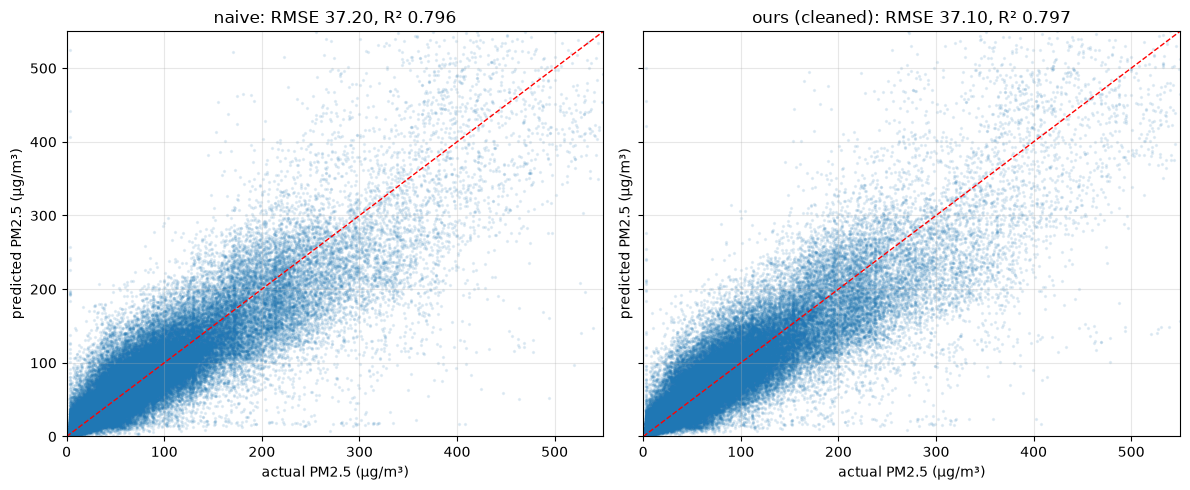

In [115]:
# predicted vs actual on the test year
lim = test_f[TARGET].quantile(0.999)
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for a, (name, p, r) in zip(ax, [("naive", pred_naive, res_naive), ("ours (cleaned)", pred_ours, res_ours)]):
    a.scatter(test_f[TARGET], p, s=2, alpha=0.1)
    a.plot([0, lim], [0, lim], "r--", lw=1)
    a.set_xlim(0, lim); a.set_ylim(0, lim)
    a.set_xlabel("actual PM2.5 (µg/m³)"); a.set_ylabel("predicted PM2.5 (µg/m³)")
    a.set_title(f"{name}: RMSE {r['RMSE']:.2f}, R² {r['R2']:.3f}")
plt.tight_layout(); plt.show()

Both models capture the overall relationship between actual and predicted PM2.5, but errors become more spread out at `higher concentrations`

The plots look similar, consistent with the modest improvement after cleaning, and this remains predicting high-pollution episodes  challenging.

,naive,ours,naive - ours,train rows naive,train rows ours,train hours PM2.5 > PM10
station,,,,,,
Wanliu,35.56,34.91,0.65,21343,24077,1963
Huairou,31.65,31.09,0.56,22566,23933,1523
Changping,35.36,34.93,0.43,23224,23935,1715
Nongzhanguan,36.91,36.55,0.36,24405,23914,1932
Guanyuan,38.34,38.19,0.14,22869,24066,1430
Tiantan,39.06,38.93,0.13,23359,24098,1672
Wanshouxigong,41.73,41.61,0.11,23403,24100,1684
Gucheng,38.27,38.23,0.04,23019,24155,1650
Aotizhongxin,37.21,37.41,-0.20,22511,24336,1218


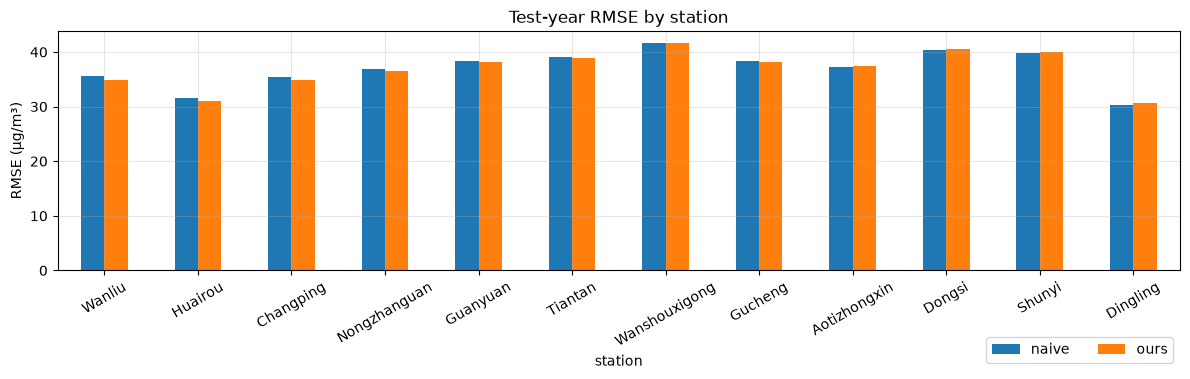

In [116]:
# RMSE per station
err = test_f[["station", TARGET]].copy()
err["naive"] = (pred_naive - err[TARGET]) ** 2
err["ours"] = (pred_ours - err[TARGET]) ** 2
by_station = np.sqrt(err.groupby("station")[["naive", "ours"]].mean())
by_station["naive - ours"] = by_station["naive"] - by_station["ours"]
by_station["train rows naive"] = naive["station"].str.strip().str.title().value_counts()
by_station["train rows ours"] = X5["station"].value_counts()
# how many PM2.5 > PM10 hours each station had (clean_basic puts them to NaN)
pm = df[["PM2.5", "PM10"]].replace(-999, np.nan)
by_station["train hours PM2.5 > PM10"] = (pm["PM2.5"] > pm["PM10"]).groupby(df["station"].str.strip().str.title()).sum()
by_station = by_station.sort_values("naive - ours", ascending=False).round(2)
display(by_station)

by_station[["naive", "ours"]].plot(kind="bar", figsize=(12, 4), title="Test-year RMSE by station")
plt.legend(loc="upper right", bbox_to_anchor=(1.0, -0.25), ncol=2)
plt.ylabel("RMSE (µg/m³)"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

From the table and the plot, we can see that leaning improves prediction accuracy at `8` of the `12` stations, although the benefit varies. **Wanliu** and **Huairou** show the largest improvements, while **Shunyi** and **Dingling** remain almost unchanged

The overall gain therefore reflects improvements across most stations, but cleaning does not benefit every station equally

In [117]:
X_test = test_f[NUM_FEATS + CAT_FEATS]
rows, by_seed = [], {}
for seed in range(5):
    m_naive = make_pipeline(HistGradientBoostingRegressor(max_iter=300, random_state=seed)).fit(naive[NUM_FEATS + CAT_FEATS], naive[TARGET])
    m_ours = make_pipeline_v(HistGradientBoostingRegressor(max_iter=300, random_state=seed), indicator=False).fit(X5, y5)
    e = test_f[["station", TARGET]].copy()
    e["naive"] = (m_naive.predict(X_test) - e[TARGET]) ** 2
    e["ours"] = (m_ours.predict(X_test) - e[TARGET]) ** 2
    rows.append({"seed": seed, "naive RMSE": np.sqrt(e["naive"].mean()), "ours RMSE": np.sqrt(e["ours"].mean())})
    st = np.sqrt(e.groupby("station")[["naive", "ours"]].mean())
    by_seed[seed] = st["naive"] - st["ours"]

seeds6 = pd.DataFrame(rows).set_index("seed")
seeds6["naive - ours"] = seeds6["naive RMSE"] - seeds6["ours RMSE"]
display(seeds6.round(2))
print(f"mean gain {seeds6['naive - ours'].mean():.2f} ± {seeds6['naive - ours'].std():.2f} µg/m³, "
      f"ours better in {int((seeds6['naive - ours'] > 0).sum())} of 5 seeds")

# gain per station for each seed
station_seeds = pd.DataFrame(by_seed)
station_seeds["mean"] = station_seeds[list(by_seed)].mean(axis=1)
station_seeds["seeds better"] = (station_seeds[list(by_seed)] > 0).sum(axis=1)
station_seeds = station_seeds.sort_values("mean", ascending=False).round(2)
display(station_seeds)
print(f"stations better on average: {int((station_seeds['mean'] > 0).sum())} of 12")

,naive RMSE,ours RMSE,naive - ours
seed,,,
0,37.20,37.10,0.10
1,37.29,36.97,0.32
2,37.54,37.09,0.45
3,37.20,36.76,0.44
4,37.35,37.01,0.34


mean gain 0.33 ± 0.14 µg/m³, ours better in 5 of 5 seeds


,0,1,2,3,4,mean,seeds better
station,,,,,,,
Wanliu,0.65,0.79,1.10,0.69,0.93,0.83,5
Nongzhanguan,0.36,0.79,0.93,0.69,0.72,0.70,5
Wanshouxigong,0.11,0.65,0.70,1.01,0.54,0.61,5
Changping,0.43,0.26,0.82,0.69,0.79,0.60,5
Huairou,0.56,0.32,0.51,0.60,0.28,0.45,5
Dongsi,-0.27,0.49,0.41,0.60,0.37,0.32,4
Gucheng,0.04,1.02,0.31,0.02,0.01,0.28,5
Aotizhongxin,-0.20,-0.18,0.53,0.31,0.53,0.20,3
Guanyuan,0.14,0.15,0.25,0.32,-0.01,0.17,4


stations better on average: 11 of 12


We can see that our cleaned model performs better across all `five random seeds`, suggesting that the modest overall improvement is stable rather than dependent on one lucky run

Some of the stations improve consistently, while others are more sensitive to the seed. These results support the value of cleaning on this test year, without establishing performance on other test periods

## ★ HPC bonus (+10 pts) — parallel per-station cleaning
The 12 stations are independent: run `clean_basic` + your imputation **per station** with `joblib.Parallel` (or Dask) and compare wall-time for 1, 2, 4 … workers. Report the speed-up $S_p=T_1/T_p$, efficiency $E_p=S_p/p$ and the dominant step.

In [118]:
from joblib import Parallel, delayed
def clean_one_station(g):
    return clean_basic(g)            # TODO: + your imputation

groups = [g for _, g in df.groupby(df["station"].str.strip().str.title())]
# for p in [1, 2, 4, -1]:
#     t0 = time.perf_counter(); out = Parallel(n_jobs=p)(delayed(clean_one_station)(g) for g in groups)
#     print(p, time.perf_counter() - t0)

## Export for Lecture 2
Save your cleaned (and imputed) training years — it is the **input of the Week-2 AI Methods Shoot-out**.

In [119]:
# df_clean.drop(columns=["datetime"]).to_csv(f"beijing_clean_team{TEAM_ID}.csv.gz", index=False)

## Report template (1 page)
1. **Findings** — the issue log (dimension · station · column · period · problem · rows · fix · why).
2. **Key decisions** — imputation per gap length (Task 3 numbers), outlier policy, transforms, dropped rows and possible bias (MNAR in smog?).
3. **Impact** — naive vs cleaned test-year RMSE / MAE / R² and one plot.
4. **Lessons** — what would you ask the agency to change in how stations export data?
5. *(bonus)* HPC timings and speed-up.

<h1 style="text-align: center;">Final Summary - Air Quality Assignment</h1>

## Findings - Task 1

We audited the six dimensions of data quality and recorded the problems in an issue log. We identified **missing measurements, duplicate station-hours, inconsistent station and wind labels, −999 codes, suspicious flat PM2.5 runs, a CO unit mismatch at Nongzhanguan in 2014, `TEMP` and `O3` peak hours generally remained close to the typical peak hours, and it did not reveal strong evidence of systematic timestamp misalignment.** This audit helped us choose targeted corrections instead of cleaning blindly.

## Key decisions - Tasks 2–5

- **Task 2 - Basic cleaning:** We standardized labels, corrected CO units and timestamps, replaced invalid readings with missing values, screened flat runs, and resolved duplicate station-hours. This restored consistency and reduced repeated observations. For `PM2.5 > PM10`, the implemented code sets both readings to missing; it does not repair column swaps.

- **Task 3 - Imputation:** We compared five methods for `NO2` and `PM2.5` using `isolated` and `24-hour` masks. **Interpolation** performed best for isolated gaps, while **KNN** performed best for long gaps. We applied interpolation to internal gaps of at most three hours and KNN to remaining pollutant gaps, preserving imputation flags. This recovered missing inputs while accounting for outage length.

- **Task 4 - Outliers and transformations:** We examined flat runs and regional pollution episodes on time plots. We retained plausible pollution peaks and unconfirmed local spikes to avoid removing important environmental events. Although `log1p` reduced skewness, the log-target model performed worse on average, so the final model retained the original target scale.

- **Task 5 - Pipeline and validation:** We encoded station, wind direction, and time cycles and compared `four preprocessing variants` using `five chronological validation folds`. We selected the nearly tied variant without missing indicators. Pipeline imputation, scaling, and encoding were fitted within each fold; however, Task 3 imputation used the full training period beforehand, so the complete CV workflow still contains leakage.

Basic cleaning removed `2,298` records overall. A further `28,822` rows lacked eligible measured PM2.5 targets and were excluded from modelling. We never trained on imputed targets. These exclusions may bias the sample if missing or rejected measurements disproportionately occur during difficult pollution conditions.

## Impact - Task 6

We trained the same regression model on the `naive` and `cleaned` datasets and evaluated both on the same complete-case final-year observations. Cleaning reduced **RMSE from 37.198 to 37.098 µg/m³** and **MAE from 22.247 to 22.105 µg/m³**, while **R² increased from 0.796 to 0.797**.

The benefit was small but positive overall in all five model seeds. Dingling worsened consistently, showing that cleaning did not benefit every station. Complete-case testing also leaves performance under missing-input conditions unverified.

**Plot:** The existing Task 6 predicted-versus-actual figure shows similar predictions for both models and wider errors at high concentrations, consistent with the modest overall gain.

## Lessons for the agency

- Use canonical station identifiers.
- Specify units and time zones explicitly.
- Use proper missing-value markers.
- Keep revision metadata for duplicate exports.
- Preserve quality flags and genuine pollution episodes.
- Validate the entire preprocessing workflow chronologically.
- Check that cleaning does not remove too many genuine high-pollution readings.

<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>